El siguiente código sirve para determinar la ecuación de la catenaria dando los puntos de sujeción de los dos postes, como además la longitud del vano real.

Éste último se debe calcular de distintas maneras posibles, como se considera inicialmente que no serán parábolas tan pronunciadas se tomará la aproximación parabólica de la siguiente manera:

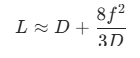

Donde:


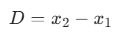


RESULTADOS
----------------------------------------
a = 1232.527728
b = 110.240000
c = -831.377728
Longitud = 81.895057
Vértice = (110.240000, 401.150000)

Ecuación:
y = 1232.527728*cosh((x-110.240000)/1232.527728) - 831.377728


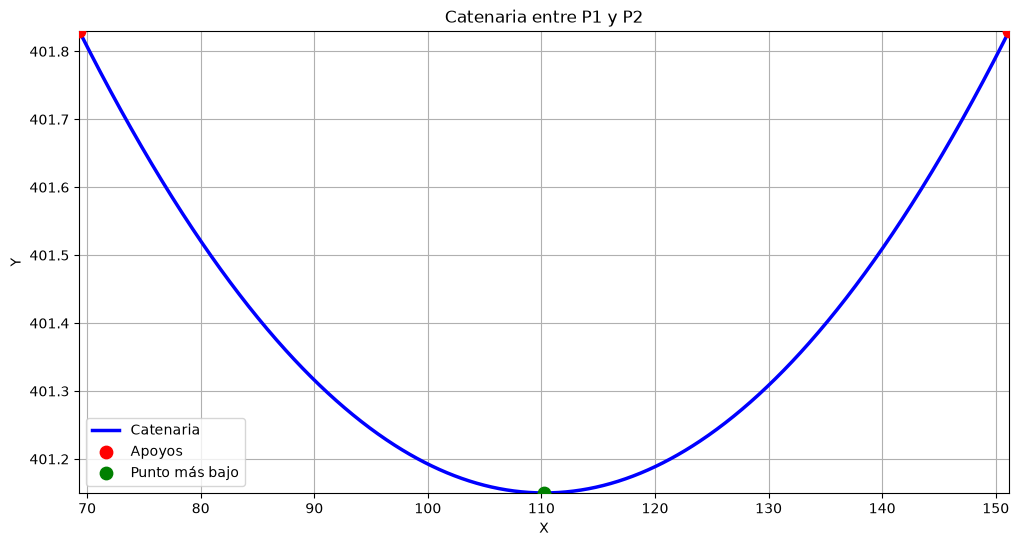

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

# =====================================================
# ENTRADA DE DATOS
# =====================================================

x1 = float(input("x1 = "))
y1 = float(input("y1 = "))

x2 = float(input("x2 = "))
y2 = float(input("y2 = "))

flecha = float(input("Flecha = "))

# =====================================================
# APOYO MÁS BAJO
# =====================================================

y_ref = min(y1, y2)

# =====================================================
# SISTEMA DE ECUACIONES
# =====================================================

def sistema(vars):
    a, b, c = vars

    eq1 = a*np.cosh((x1-b)/a) + c - y1

    eq2 = a*np.cosh((x2-b)/a) + c - y2

    # Punto más bajo de la catenaria
    y_min = a + c

    # Condición de flecha
    eq3 = (y_ref - y_min) - flecha

    return [eq1, eq2, eq3]

# =====================================================
# ESTIMACIONES INICIALES
# =====================================================

a0 = abs(x2-x1)
b0 = (x1+x2)/2
c0 = y_ref - flecha - abs(x2-x1)/2

a, b, c = fsolve(sistema, [a0, b0, c0])

# =====================================================
# LONGITUD DE LA CATENARIA
# =====================================================

L = a*(
    np.sinh((x2-b)/a)
    - np.sinh((x1-b)/a)
)

# =====================================================
# RESULTADOS
# =====================================================

print("\nRESULTADOS")
print("-"*40)
print(f"a = {a:.6f}")
print(f"b = {b:.6f}")
print(f"c = {c:.6f}")
print(f"Longitud = {L:.6f}")

xv = b
yv = a + c

print(f"Vértice = ({xv:.6f}, {yv:.6f})")

# =====================================================
# ECUACIÓN
# =====================================================

print("\nEcuación:")

if c >= 0:
    print(
        f"y = {a:.6f}*cosh((x-{b:.6f})/{a:.6f}) + {c:.6f}"
    )
else:
    print(
        f"y = {a:.6f}*cosh((x-{b:.6f})/{a:.6f}) - {abs(c):.6f}"
    )

# =====================================================
# GRAFICAR
# =====================================================

x = np.linspace(
    min(x1, x2),
    max(x1, x2),
    1000
)

y = a*np.cosh((x-b)/a) + c

plt.figure(figsize=(12,6))

plt.plot(
    x,
    y,
    color='blue',
    linewidth=2.5,
    label='Catenaria'
)

plt.scatter(
    [x1, x2],
    [y1, y2],
    color='red',
    s=80,
    zorder=5,
    label='Apoyos'
)

plt.scatter(
    xv,
    yv,
    color='green',
    s=80,
    zorder=5,
    label='Punto más bajo'
)

plt.xlim(min(x1, x2), max(x1, x2))

ymin = min(y.min(), y1, y2)
ymax = max(y.max(), y1, y2)

plt.ylim(ymin, ymax)

plt.grid(True)
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Catenaria entre P1 y P2')
plt.legend()

plt.show()

El siguiente programa ejecuta dos catenarias.



In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

# =====================================================
# FUNCIÓN PARA CALCULAR UNA CATENARIA
# =====================================================

def calcular_catenaria(x1, y1, x2, y2, flecha):

    y_ref = min(y1, y2)

    def sistema(vars):
        a, b, c = vars

        eq1 = a*np.cosh((x1-b)/a) + c - y1
        eq2 = a*np.cosh((x2-b)/a) + c - y2

        y_min = a + c

        eq3 = (y_ref - y_min) - flecha

        return [eq1, eq2, eq3]

    a0 = abs(x2-x1)
    b0 = (x1+x2)/2
    c0 = y_ref - flecha - a0

    a, b, c = fsolve(sistema, [a0, b0, c0])

    L = a * (
        np.sinh((x2-b)/a)
        - np.sinh((x1-b)/a)
    )

    return a, b, c, abs(L)

# =====================================================
# ENTRADA DE DATOS
# =====================================================

print("\n===== PUNTO 1 =====")
x1 = float(input("x1 = "))
y1 = float(input("y1 = "))

print("\n===== PUNTO 2 =====")
x2 = float(input("x2 = "))
y2 = float(input("y2 = "))

print("\n===== PUNTO 3 =====")
x3 = float(input("x3 = "))
y3 = float(input("y3 = "))

print("\n===== FLECHAS =====")
f1 = float(input("Flecha vano 1 (P1-P2): "))
f2 = float(input("Flecha vano 2 (P2-P3): "))

# =====================================================
# CATENARIA 1
# =====================================================

a1, b1, c1, L1 = calcular_catenaria(
    x1, y1,
    x2, y2,
    f1
)

# =====================================================
# CATENARIA 2
# =====================================================

a2, b2, c2, L2 = calcular_catenaria(
    x2, y2,
    x3, y3,
    f2
)

# =====================================================
# RESULTADOS
# =====================================================

print("\n================================")
print("RESULTADOS")
print("================================")

print(f"\nLongitud vano 1 = {L1:.3f} m")
print(f"Longitud vano 2 = {L2:.3f} m")
print(f"Longitud total  = {L1+L2:.3f} m")

print("\nCATENARIA 1")
print(f"a = {a1:.6f}")
print(f"b = {b1:.6f}")
print(f"c = {c1:.6f}")

print("\nCATENARIA 2")
print(f"a = {a2:.6f}")
print(f"b = {b2:.6f}")
print(f"c = {c2:.6f}")

# =====================================================
# GRAFICAR
# =====================================================

x_vano1 = np.linspace(x1, x2, 1000)
y_vano1 = a1*np.cosh((x_vano1-b1)/a1) + c1

x_vano2 = np.linspace(x2, x3, 1000)
y_vano2 = a2*np.cosh((x_vano2-b2)/a2) + c2

plt.figure(figsize=(14,6))

plt.plot(
    x_vano1,
    y_vano1,
    color="blue",
    linewidth=2.5,
    label=f"Vano 1   L={L1:.2f}"
)

plt.plot(
    x_vano2,
    y_vano2,
    color="green",
    linewidth=2.5,
    label=f"Vano 2   L={L2:.2f}"
)

plt.scatter(
    [x1, x2, x3],
    [y1, y2, y3],
    color="red",
    s=100,
    zorder=10
)

plt.annotate("P1",(x1,y1))
plt.annotate("P2",(x2,y2))
plt.annotate("P3",(x3,y3))

plt.grid(True)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Dos catenarias consecutivas")
plt.legend()

plt.show()


===== PUNTO 1 =====


ValueError: could not convert string to float: ''

El siguiente código valida los datos de entrada con los cuales se calcularán las catenarias

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
from pathlib import Path

df=pd.read_excel("DATOS.xlsx")
df




,Apoyo,Coordenada en X,Coordenada en Y,Vano,Flecha
0,AP001,0.00,401.83,0.00,0.000000
1,AP002,69.30,401.83,69.30,0.676483
2,AP003,151.18,400.00,81.88,0.872259
3,AP004,281.25,397.66,130.07,2.203515
4,AP005,504.86,399.95,223.61,6.104488
...,...,...,...,...,...
121,AP123,17020.48,411.15,184.55,4.129412
122,AP124,17111.46,406.37,90.98,1.091468
123,AP125,17246.78,393.99,135.32,2.540771
124,AP126,17313.78,379.00,67.00,0.676483


El siguiente programa genera el abscisado de los puntos y establece los márgenes en el eje Y, mejorando la gráfica del plantillado.

Además exporta la gráfica en DXF en escala 1:1

Puntos detectados : 126
Vanos detectados  : 125
Flechas detectadas: 125
Vano 01 | AP001 -> AP002 | L = 69.32 m
Vano 02 | AP002 -> AP003 | L = 81.99 m
Vano 03 | AP003 -> AP004 | L = 130.31 m
Vano 04 | AP004 -> AP005 | L = 224.24 m
Vano 05 | AP005 -> AP006 | L = 189.77 m
Vano 06 | AP006 -> AP007 | L = 122.29 m
Vano 07 | AP007 -> AP008 | L = 95.82 m
Vano 08 | AP008 -> AP009 | L = 152.73 m
Vano 09 | AP009 -> AP010 | L = 74.07 m
Vano 10 | AP010 -> AP011 | L = 178.40 m
Vano 11 | AP011 -> AP012 | L = 94.72 m
Vano 12 | AP012 -> AP013 | L = 140.16 m
Vano 13 | AP013 -> AP014 | L = 112.07 m
Vano 14 | AP014 -> AP015 | L = 90.67 m
Vano 15 | AP015 -> AP016 | L = 121.90 m
Vano 16 | AP016 -> AP017 | L = 121.96 m
Vano 17 | AP017 -> AP018 | L = 82.85 m
Vano 18 | AP018 -> AP019 | L = 154.44 m
Vano 19 | AP019 -> AP020 | L = 133.18 m
Vano 20 | AP020 -> AP021 | L = 151.90 m
Vano 21 | AP021 -> AP023 | L = 105.66 m
Vano 22 | AP023 -> AP024 | L = 84.12 m
Vano 23 | AP024 -> AP025 | L = 152.54 m
Vano 24 | AP025 

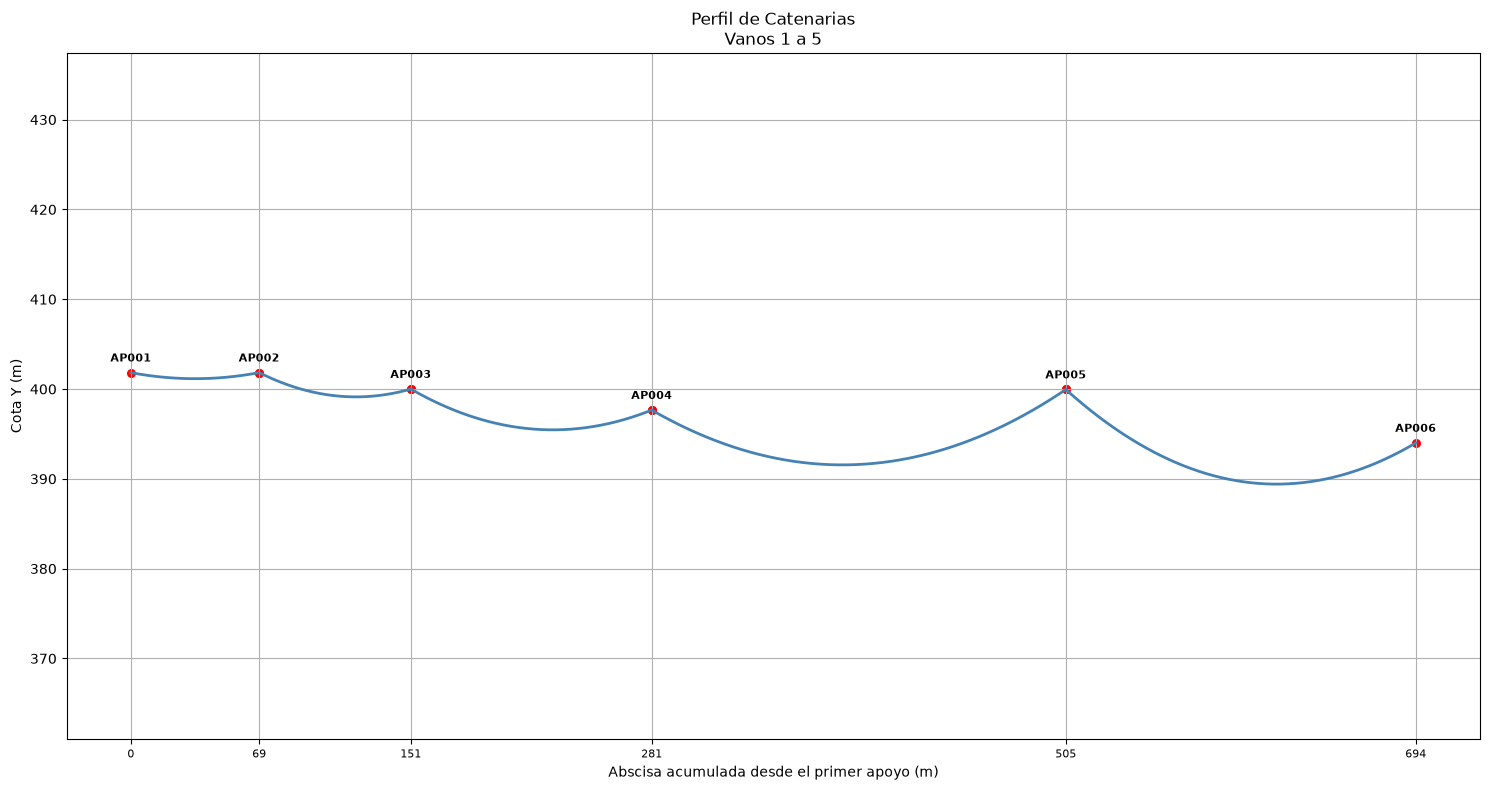

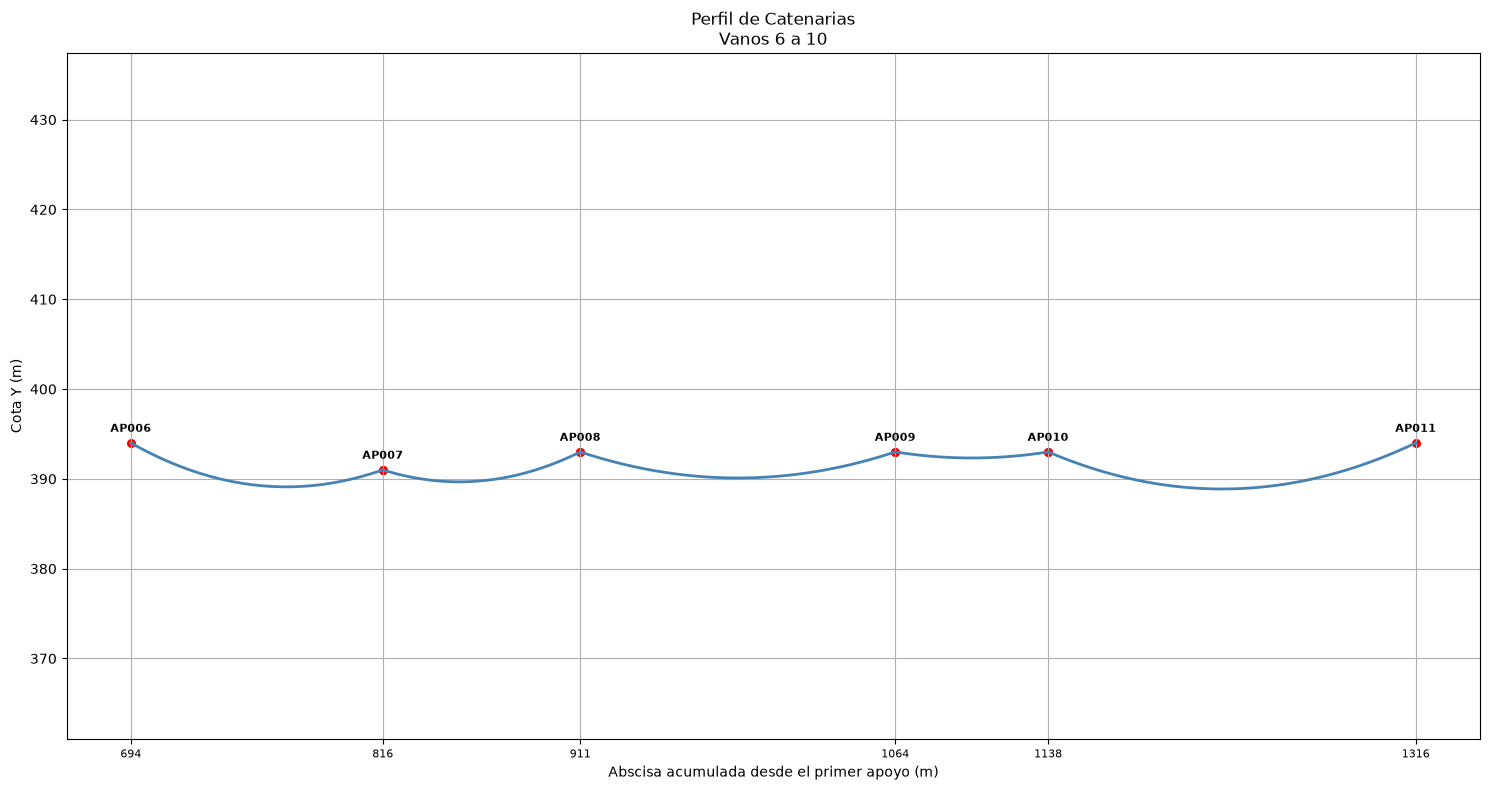

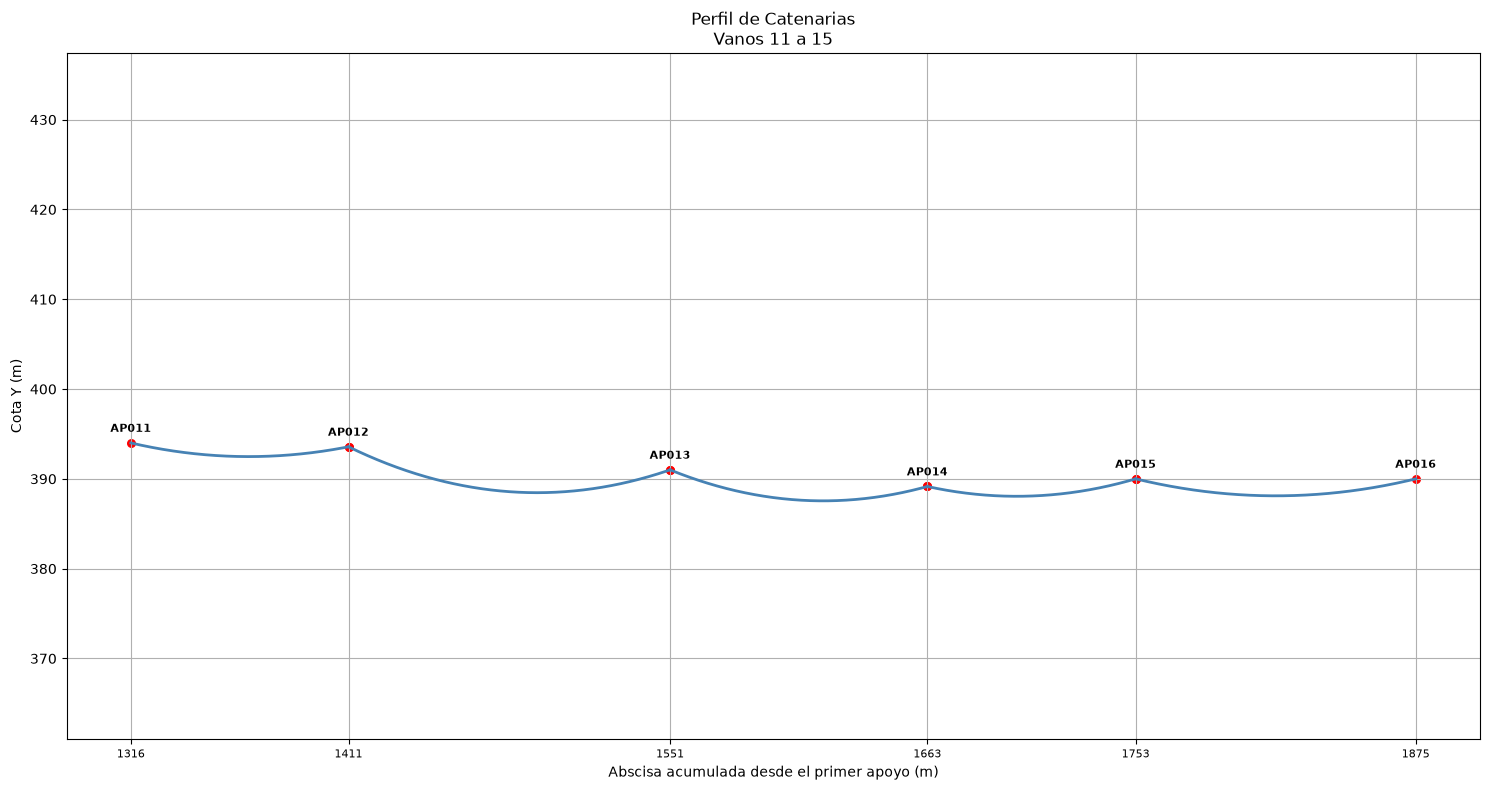

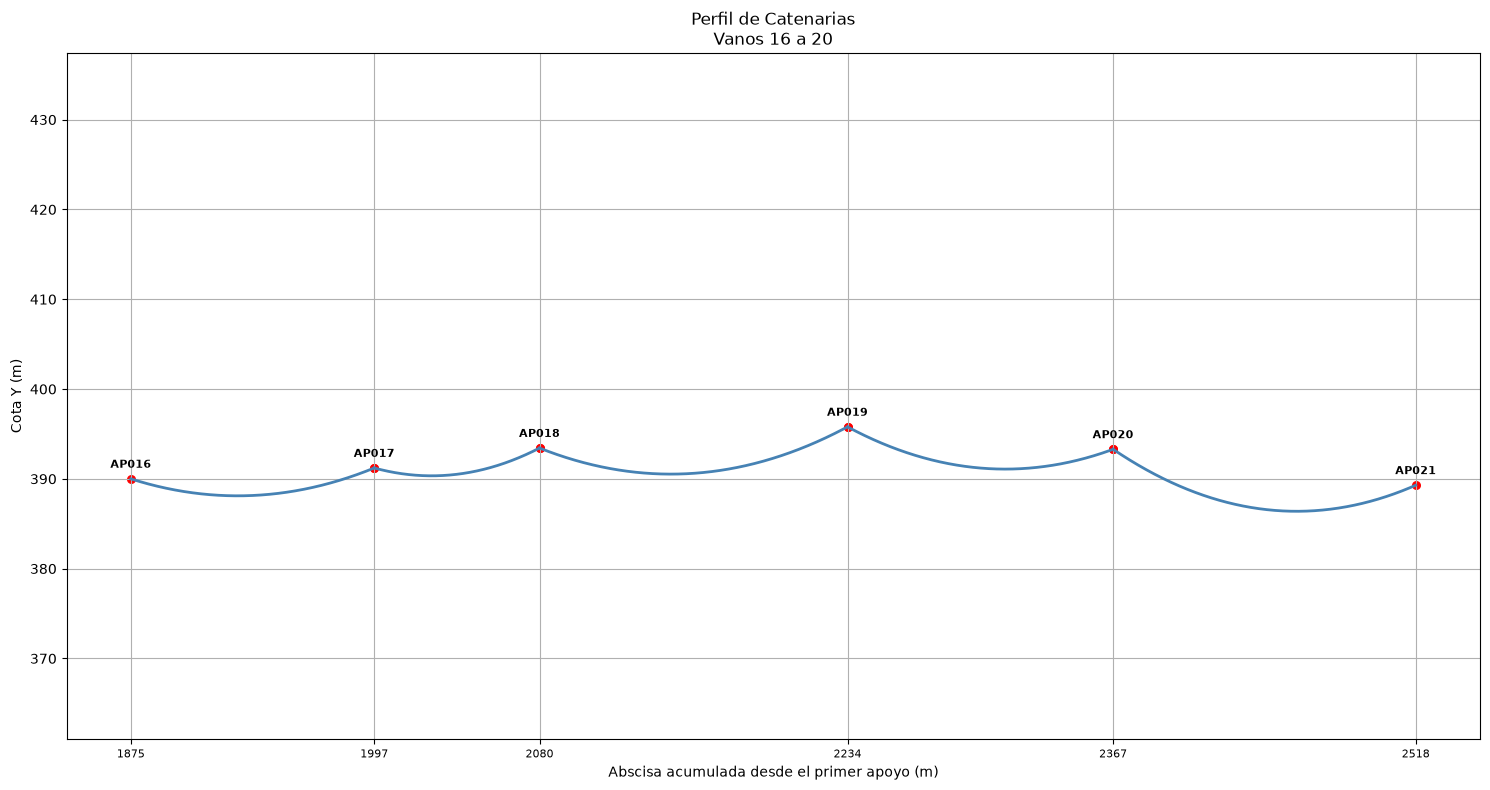

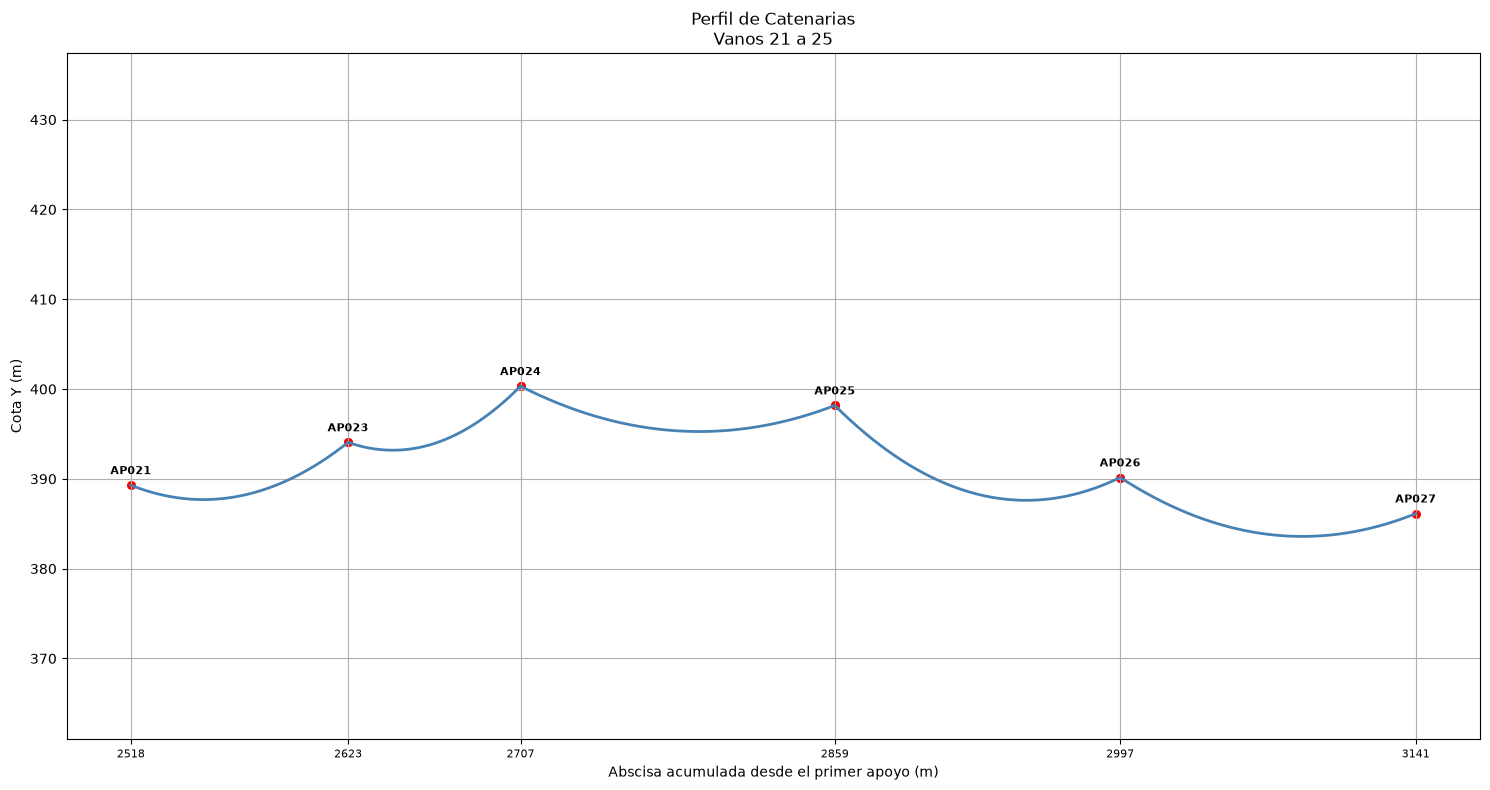

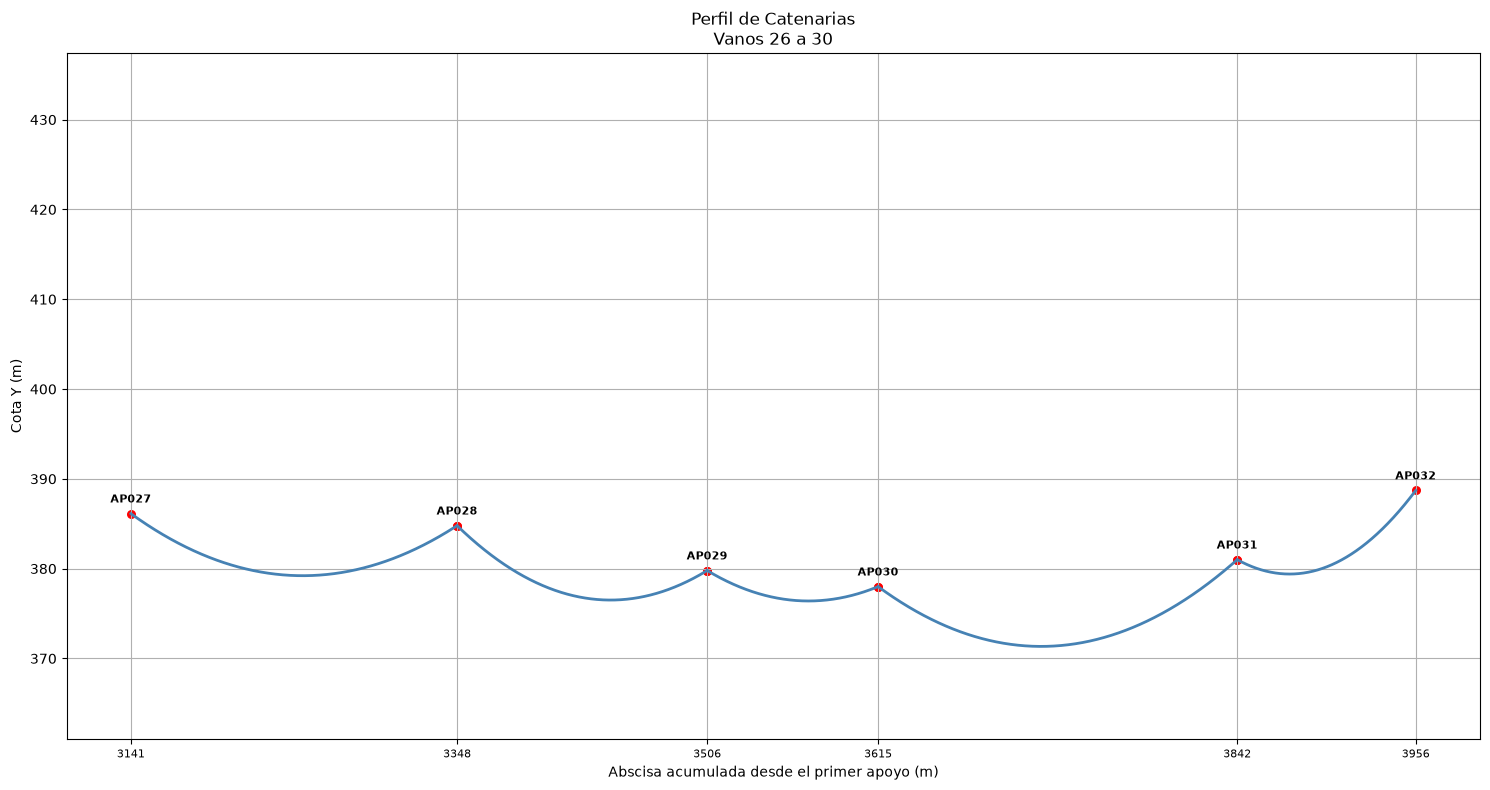

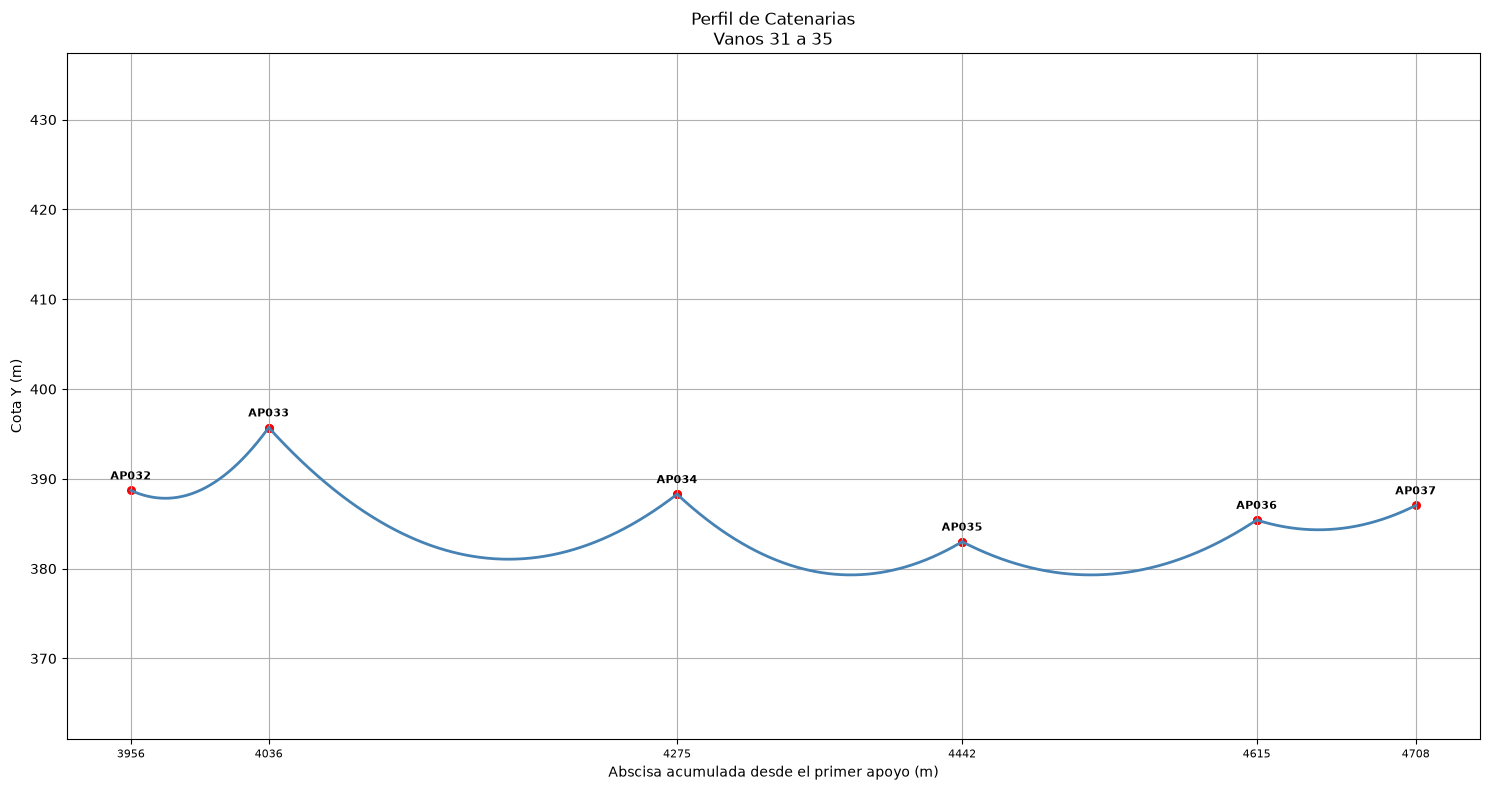

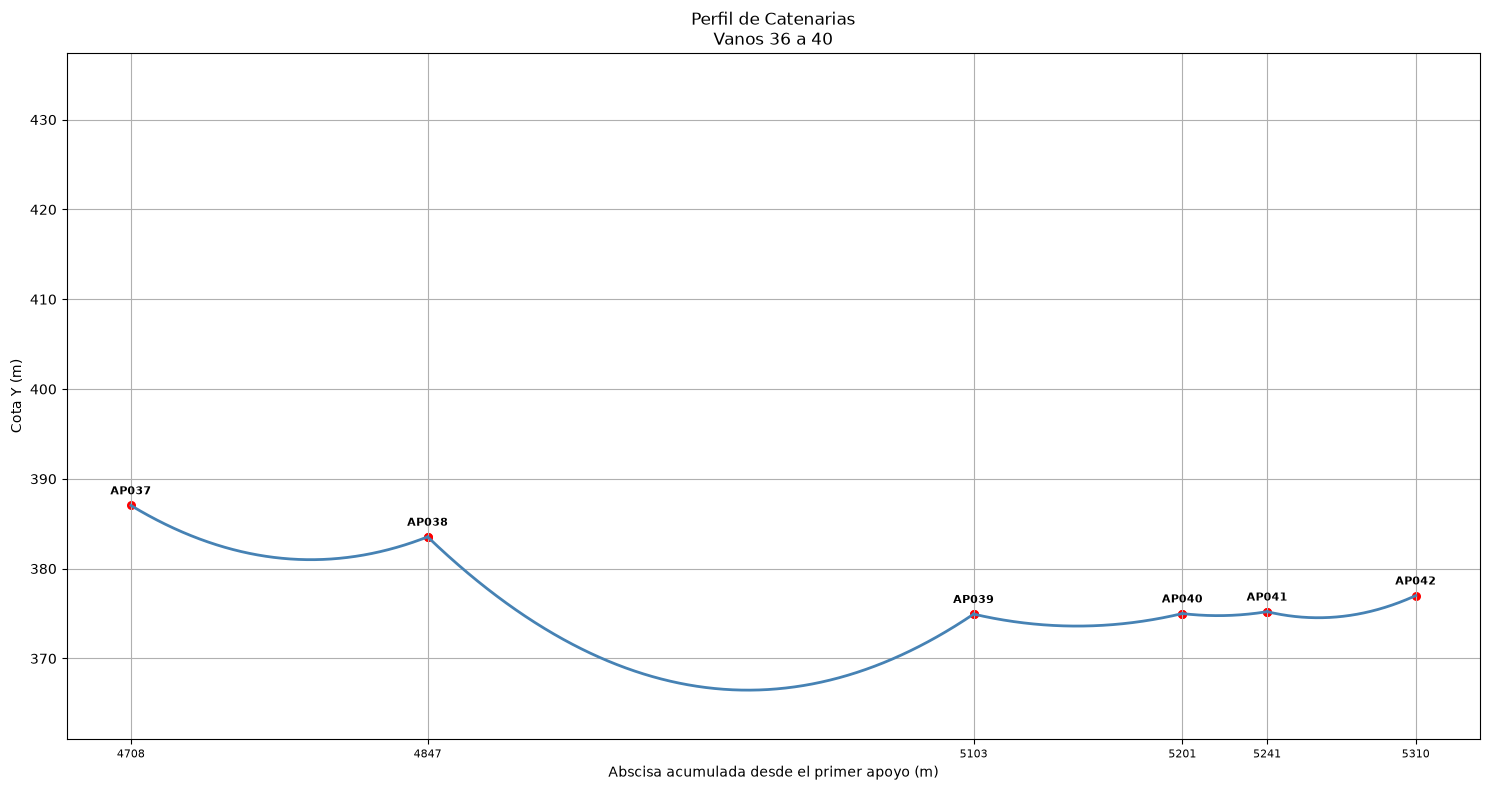

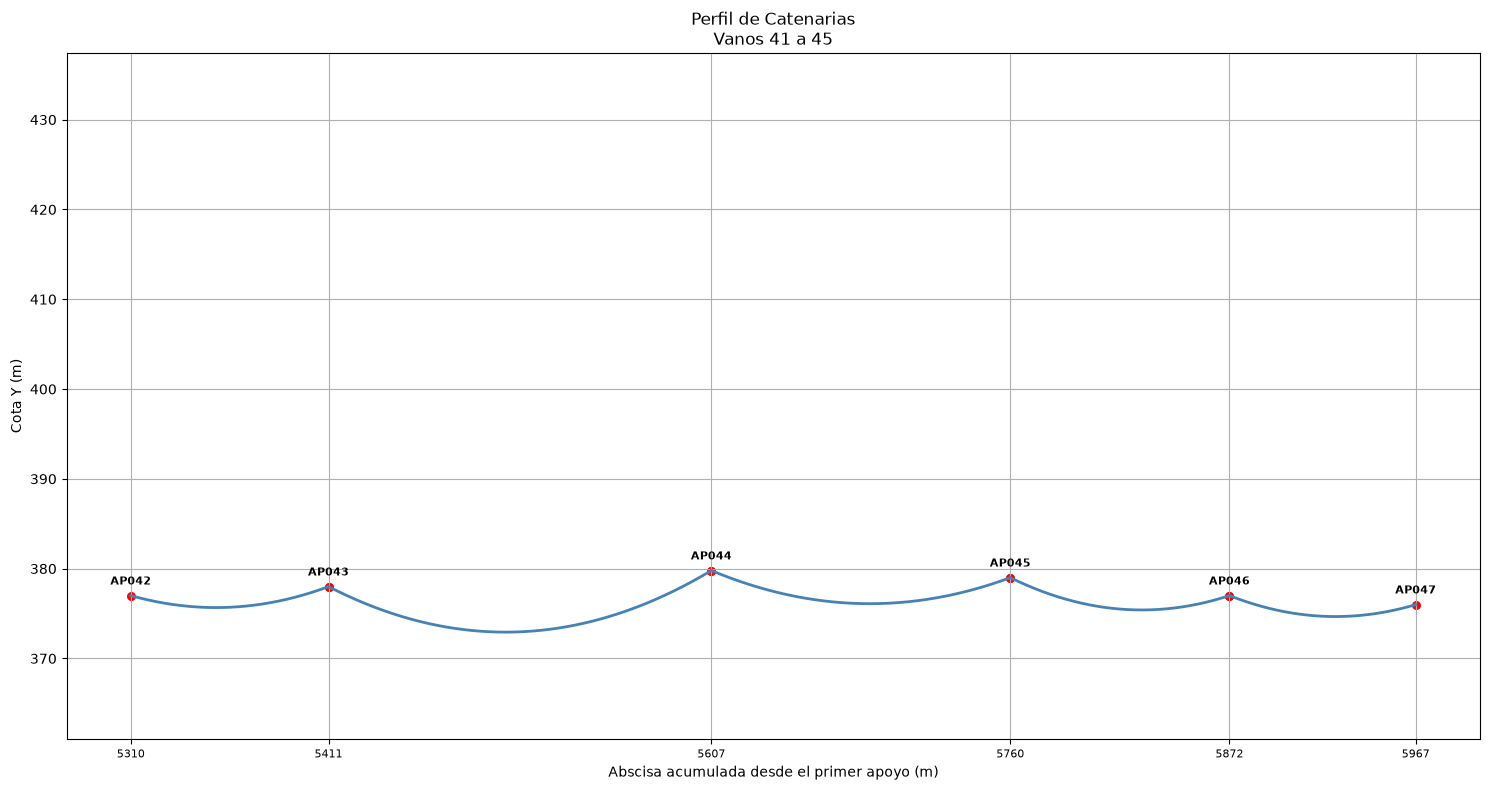

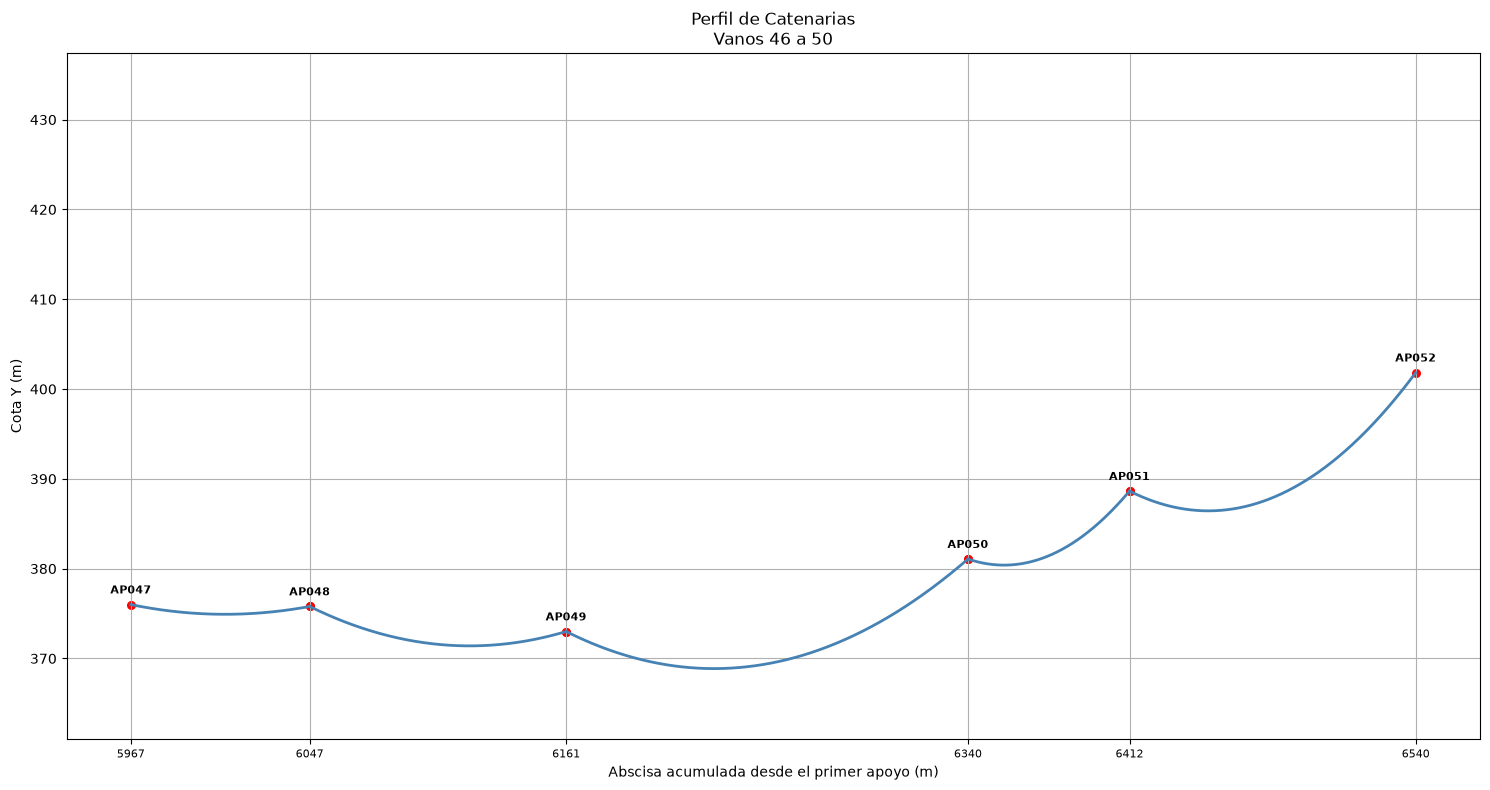

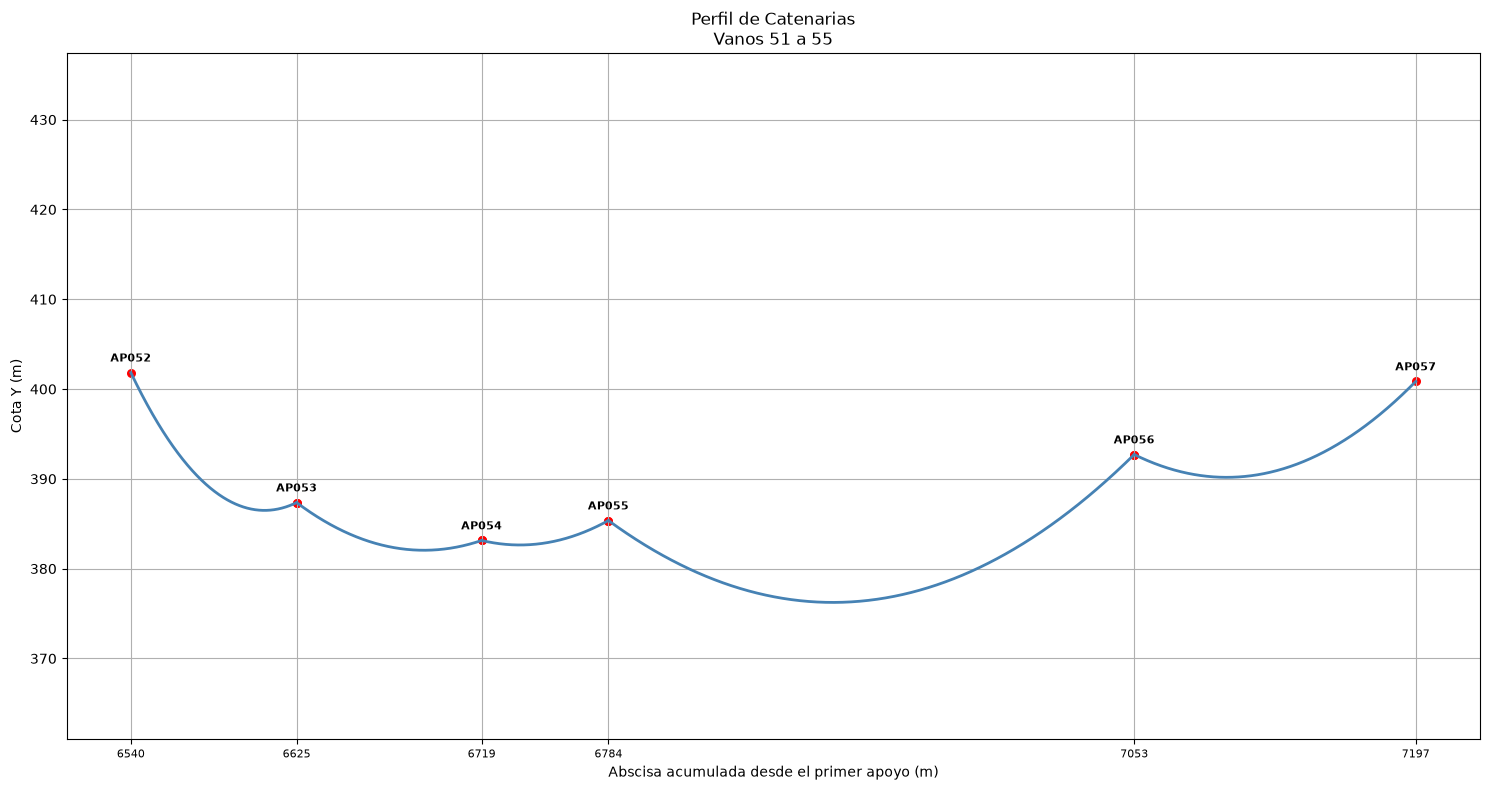

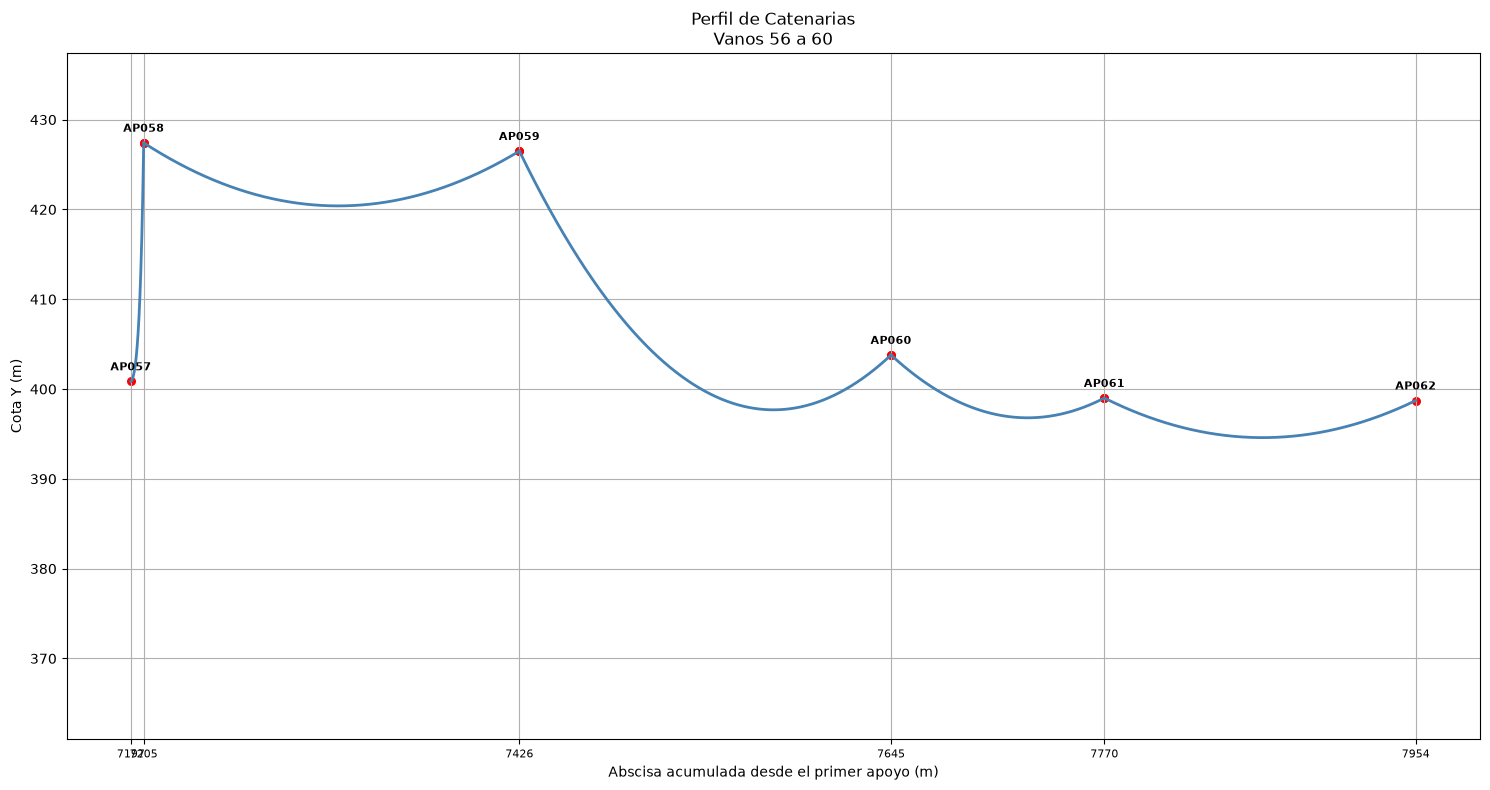

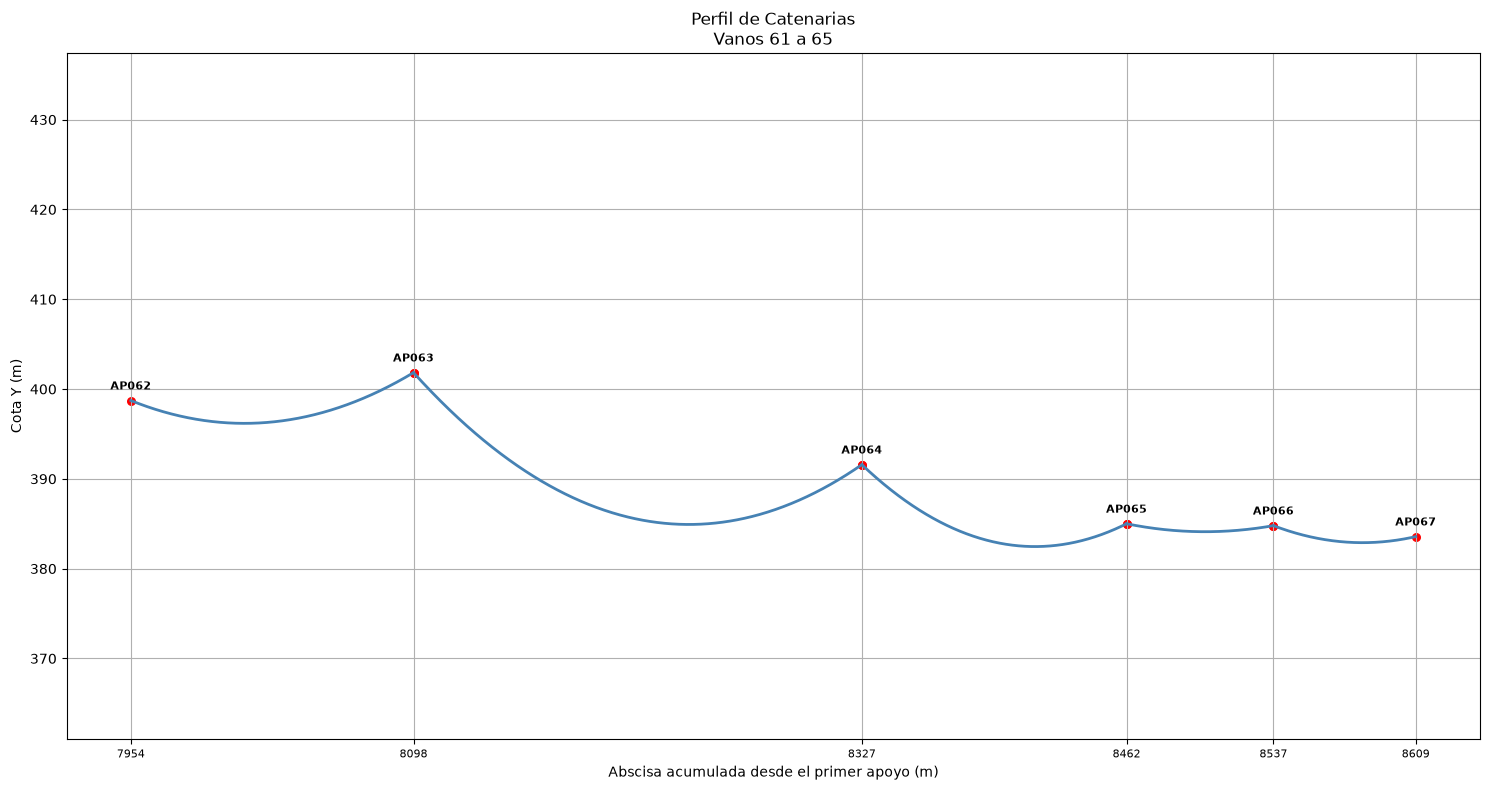

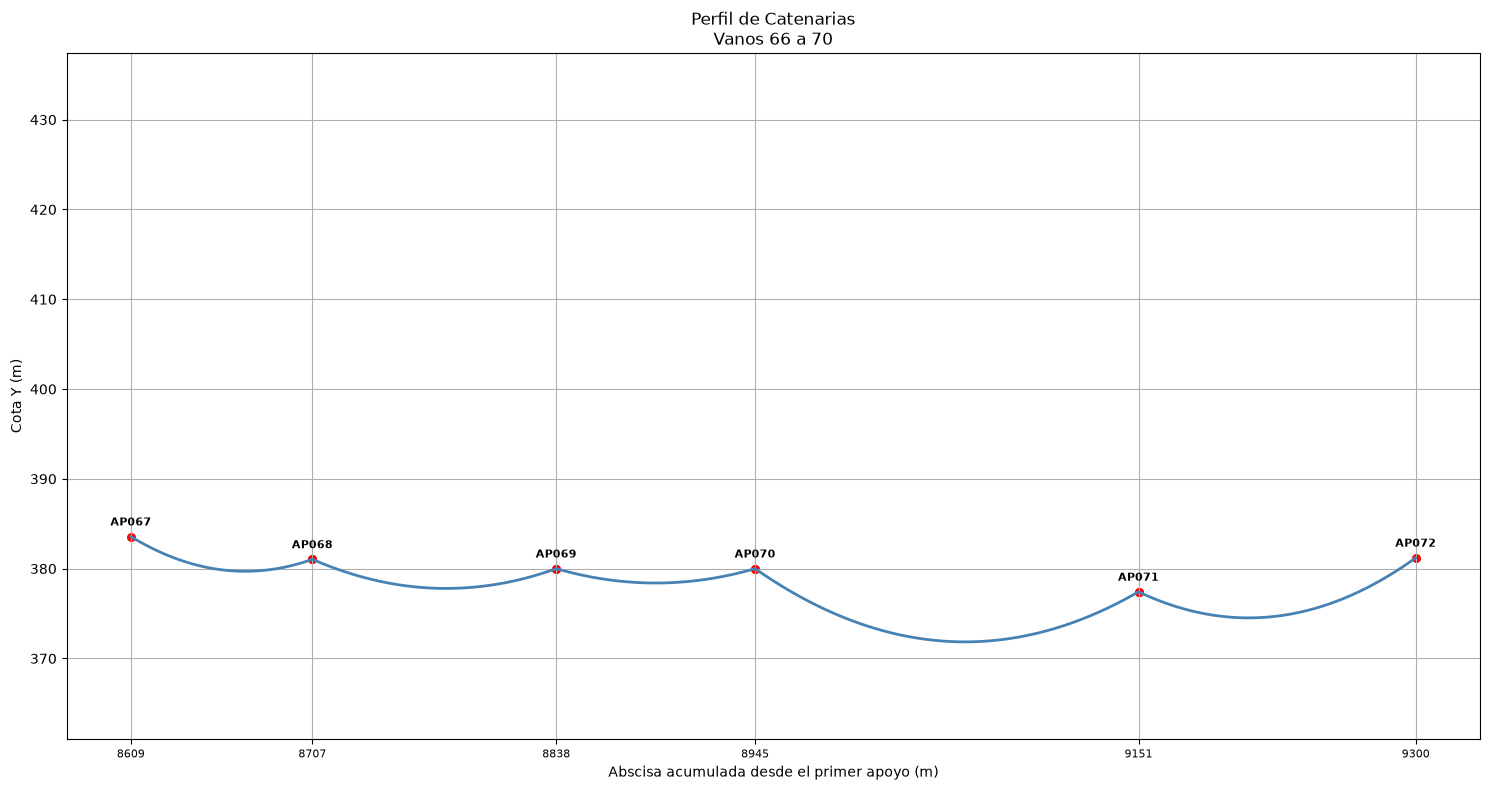

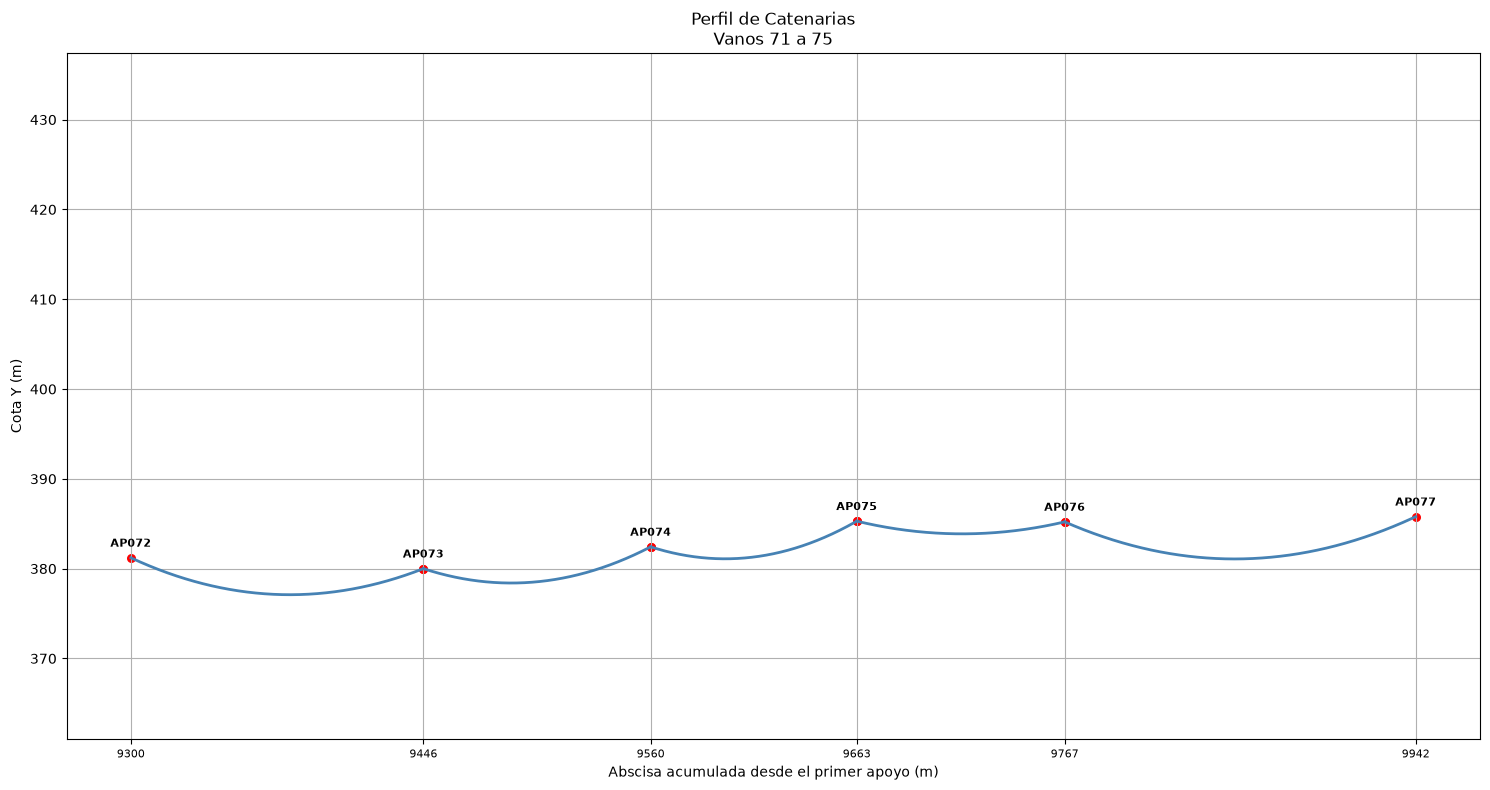

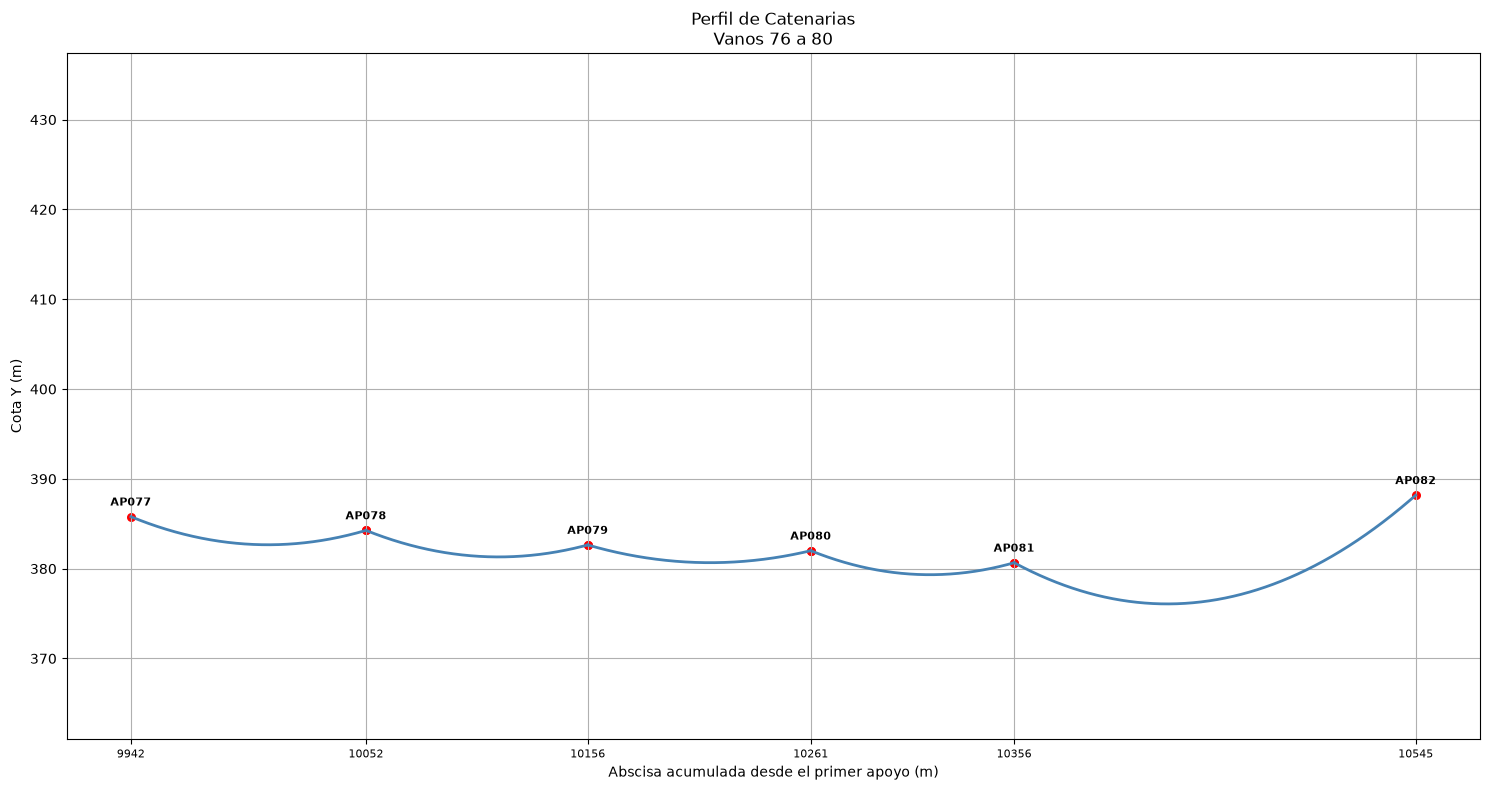

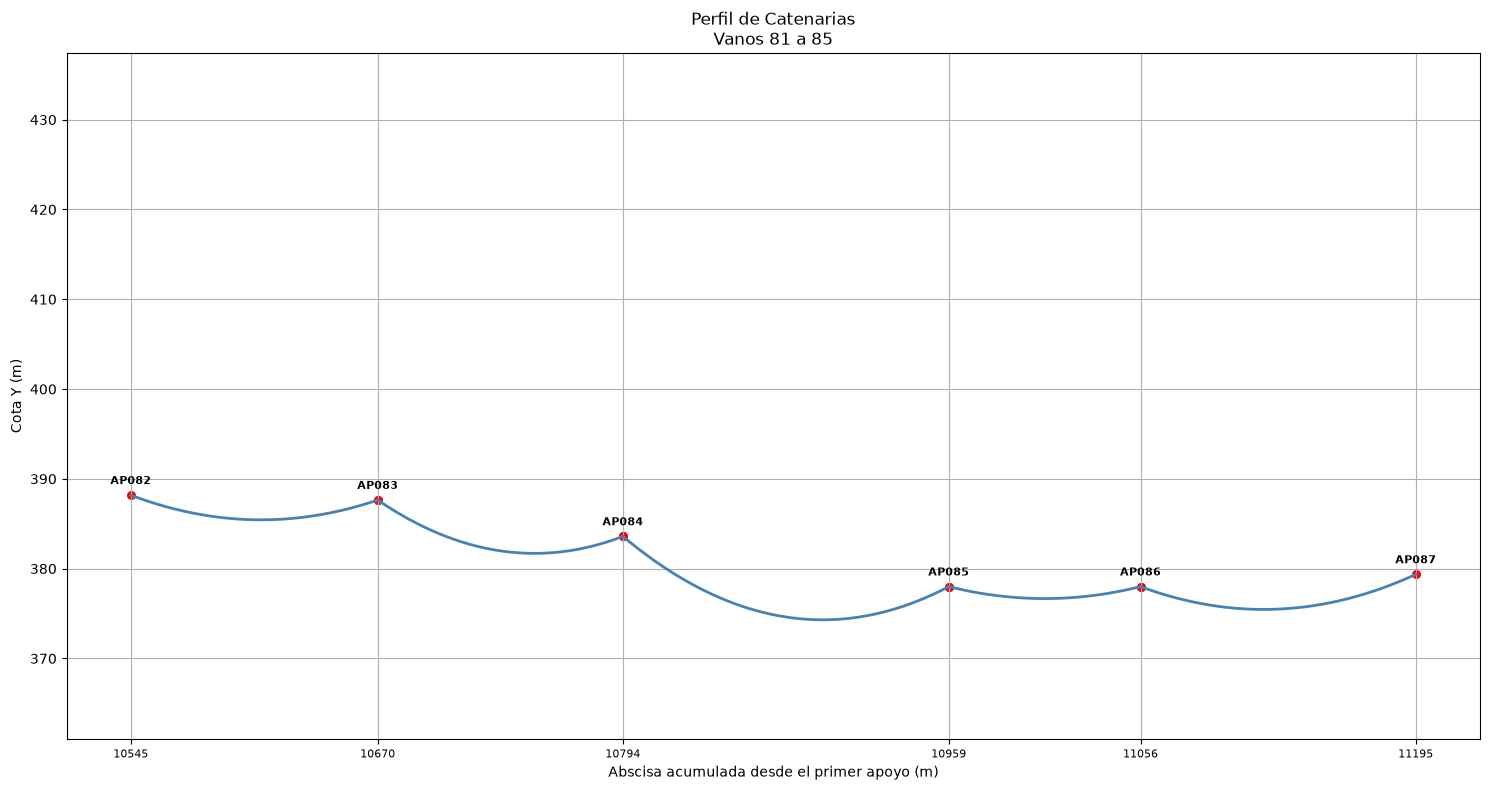

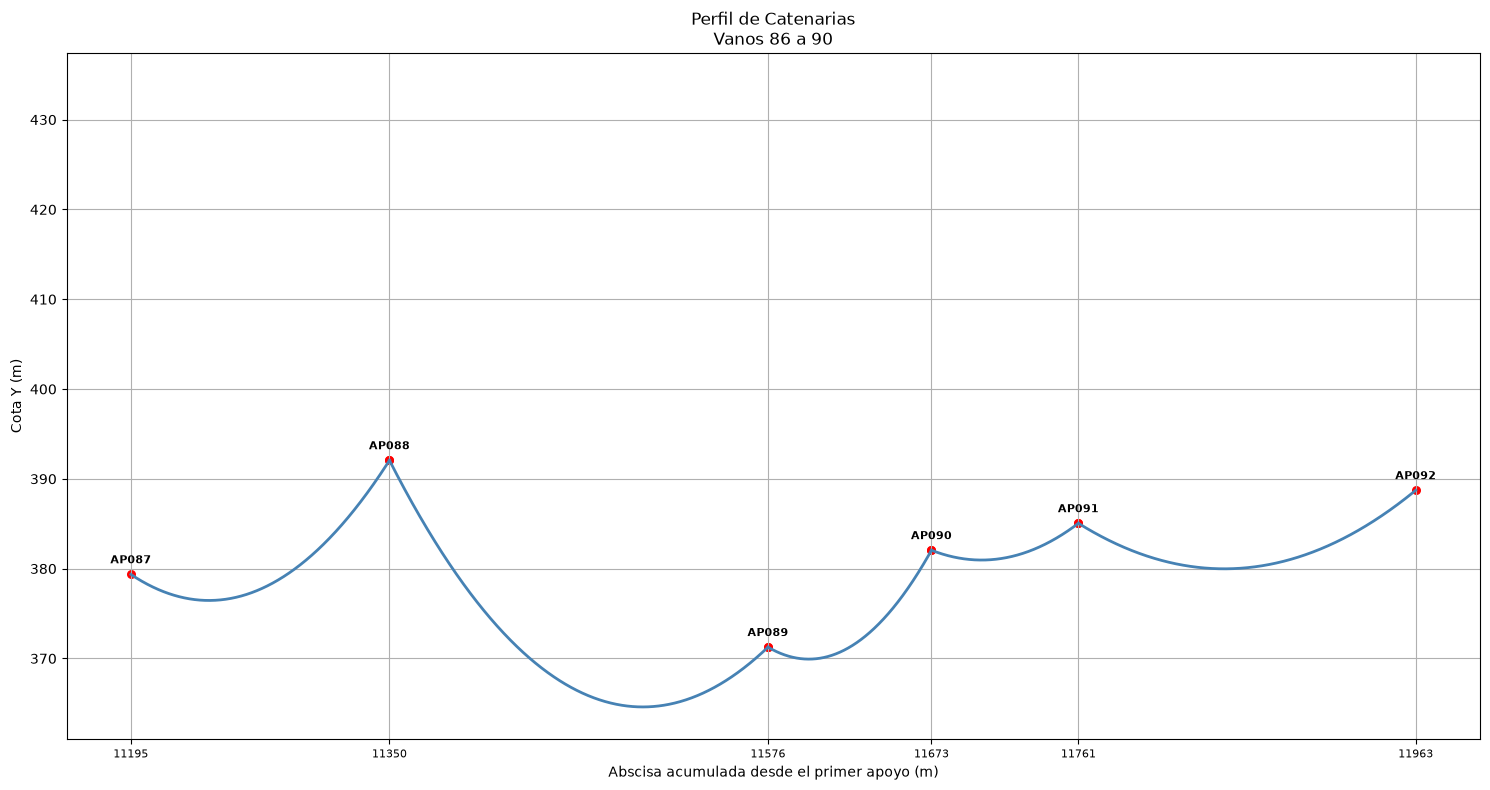

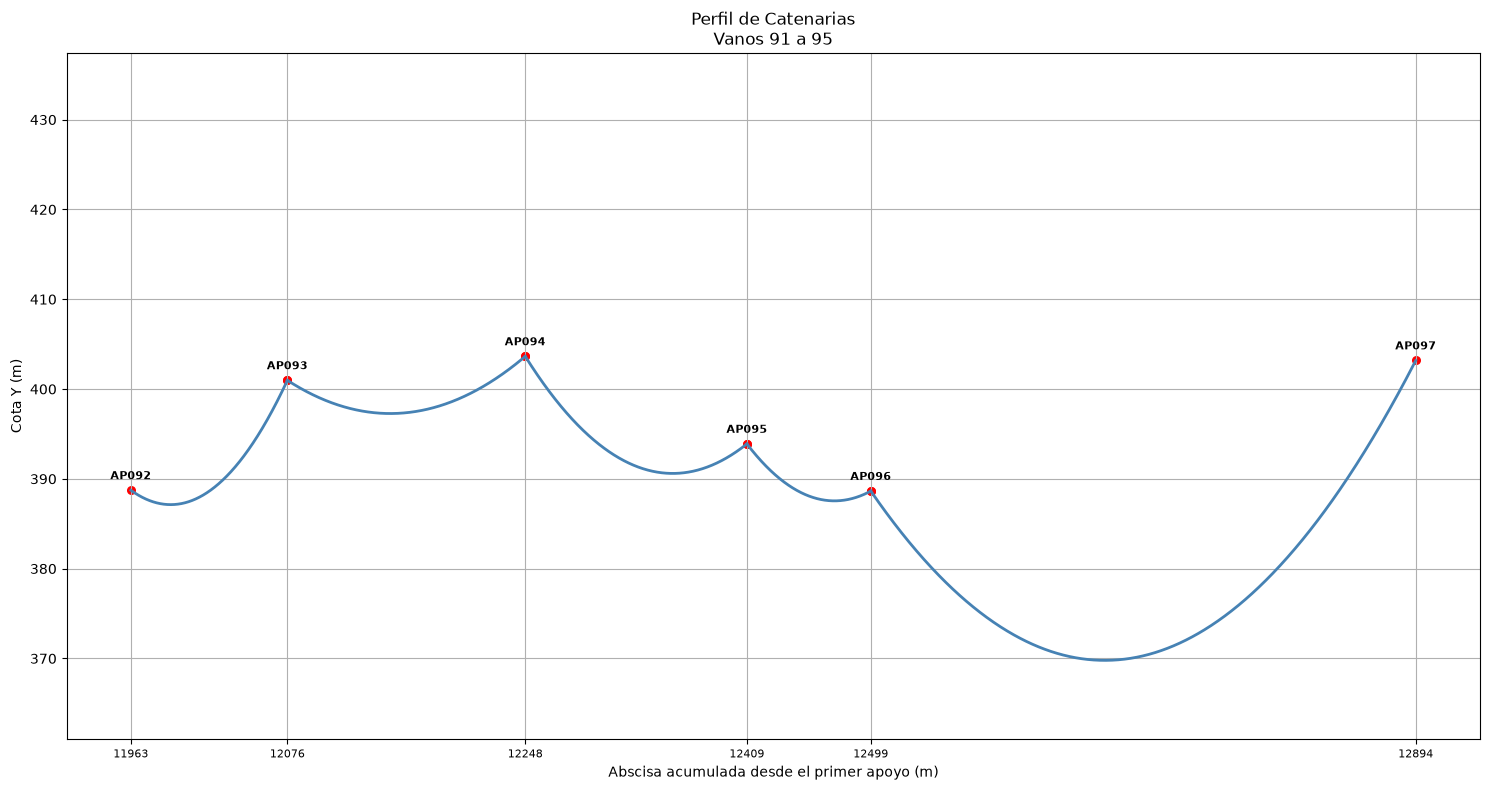

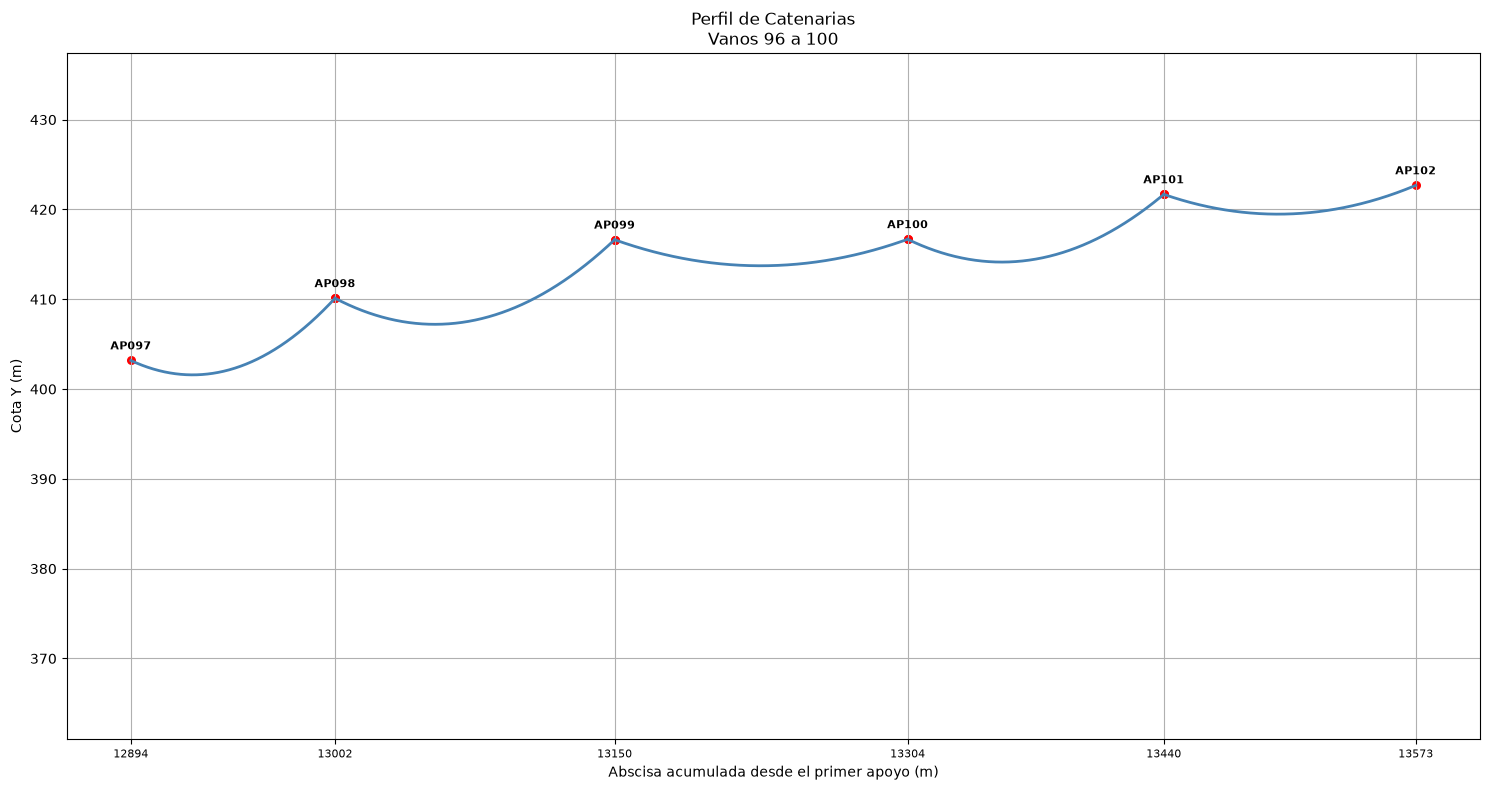

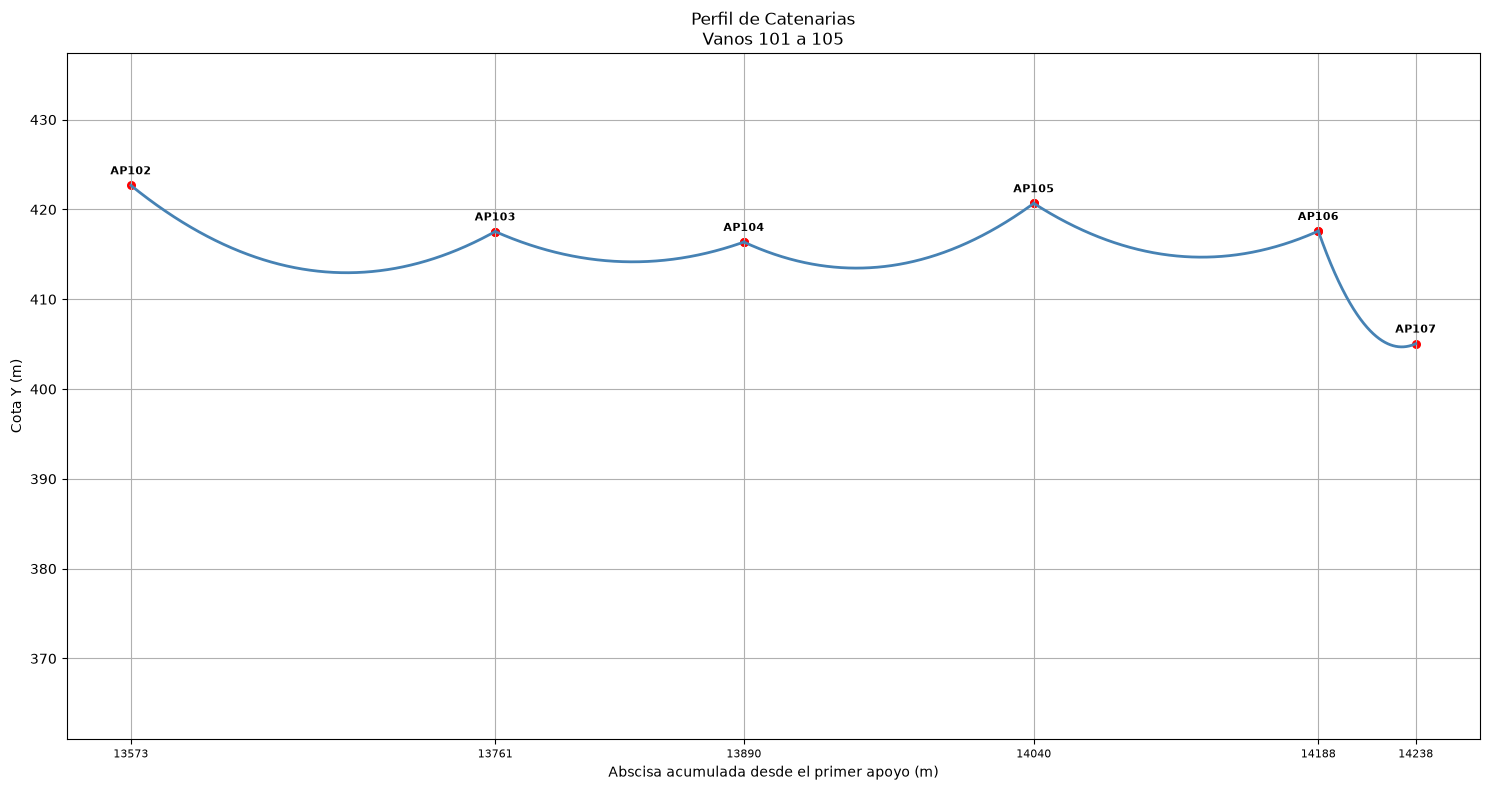

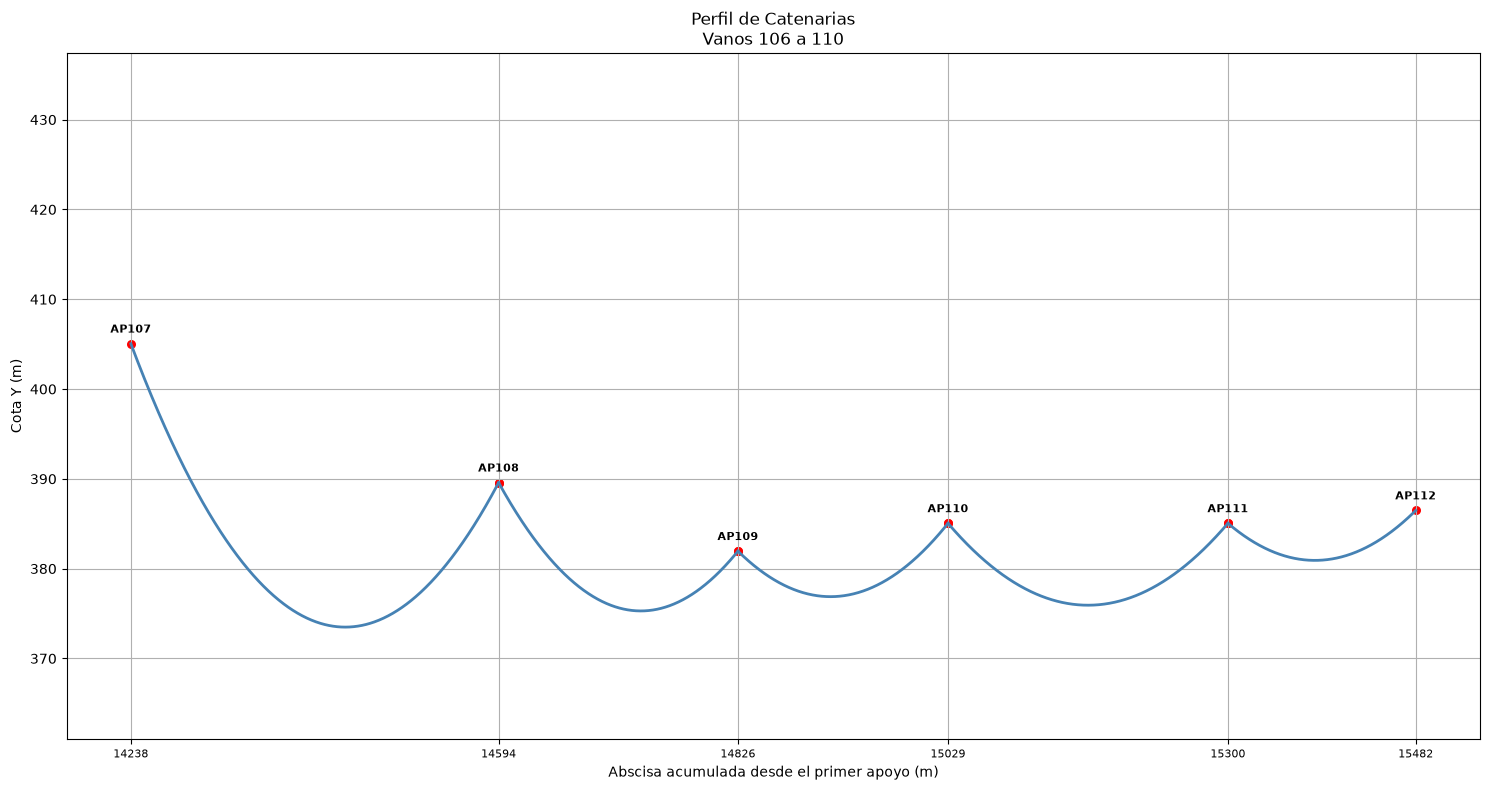

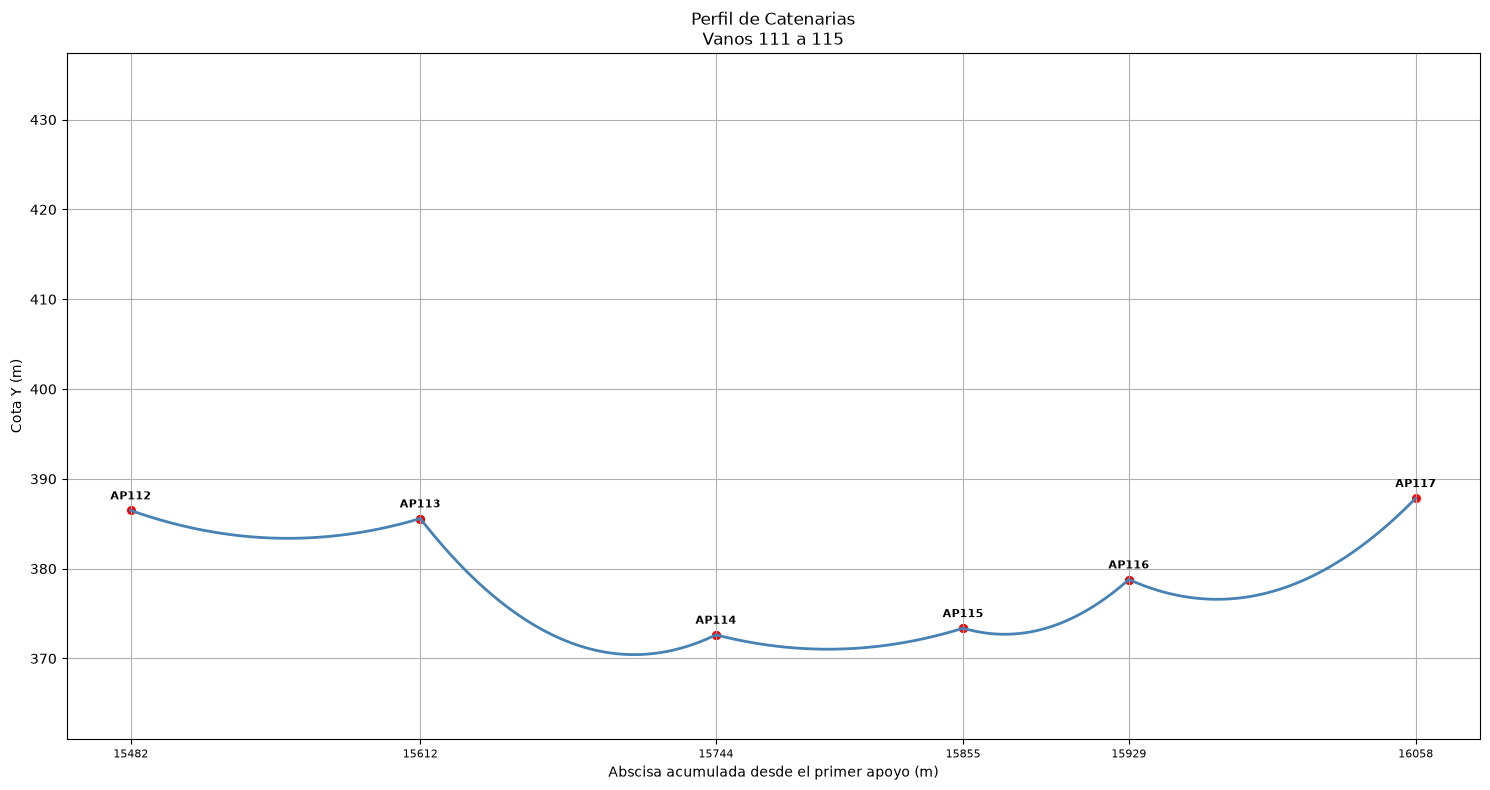

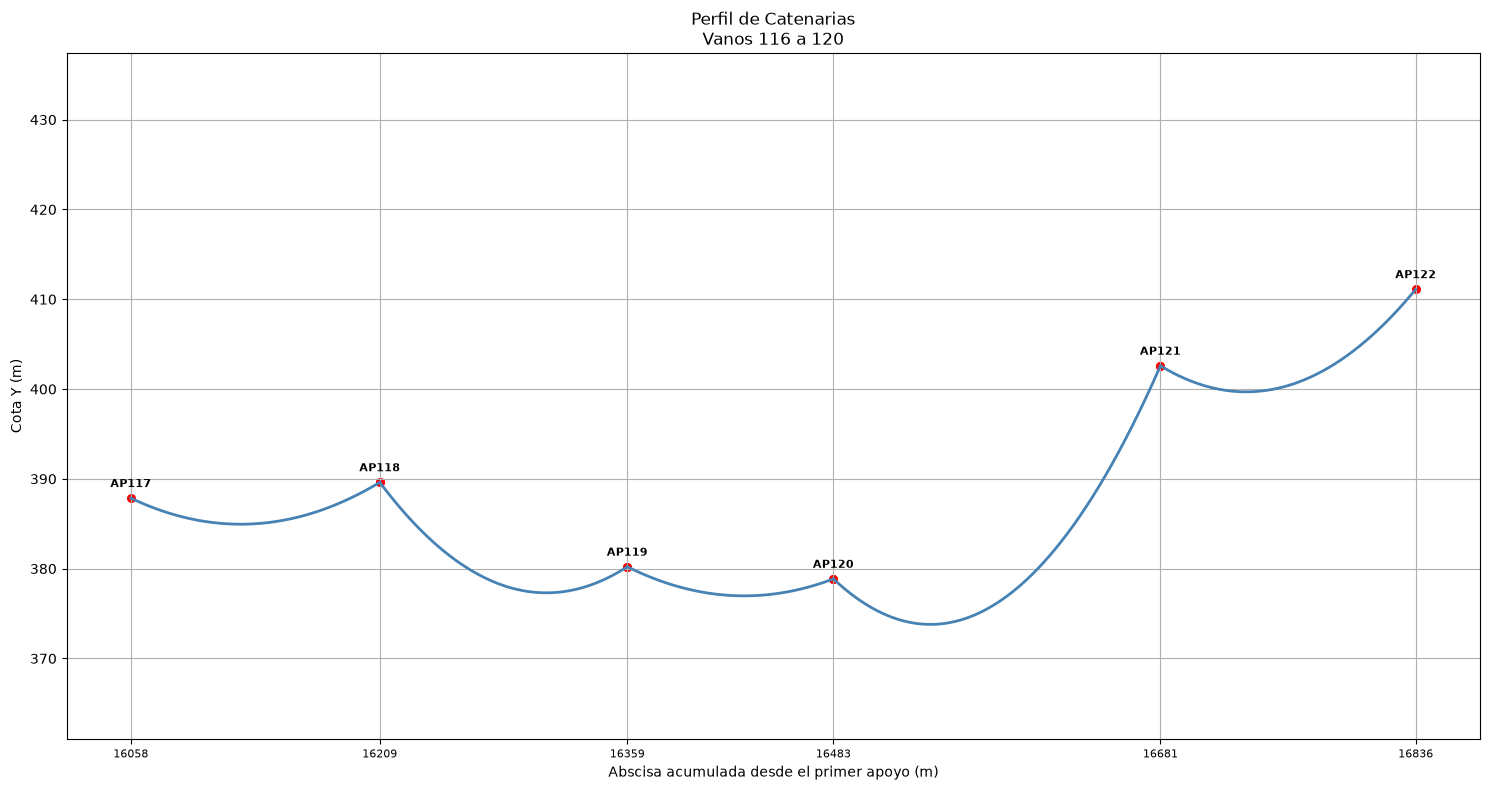

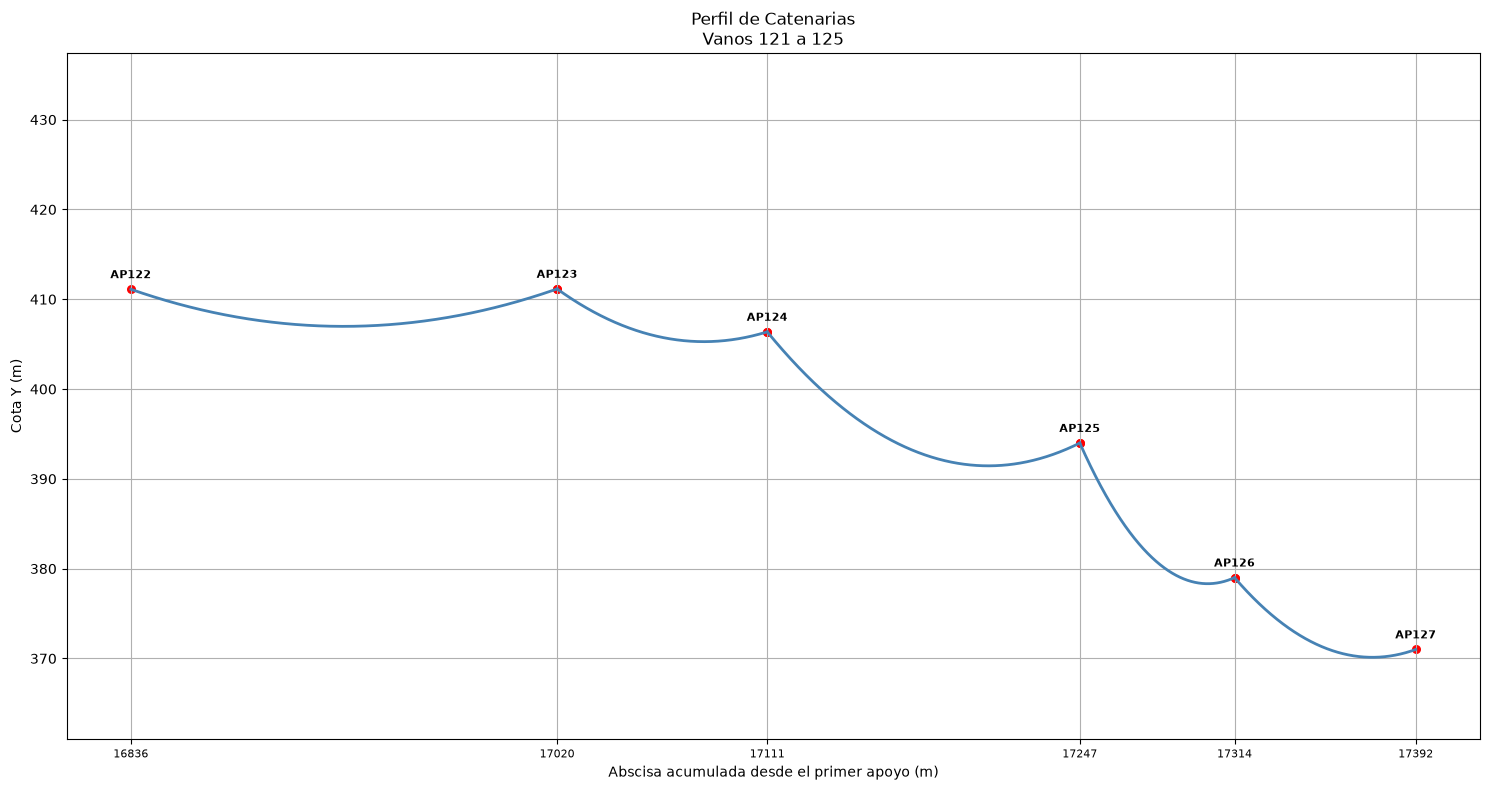


Generando DXF...
DXF generado correctamente:
PERFIL_CATENARIAS.dxf

PDF generado correctamente:
PERFIL_CATENARIAS.pdf

Excel generado correctamente:
RESULTADOS_CATENARIAS.xlsx


In [9]:
!pip install ezdxf

import ezdxf

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import fsolve
from matplotlib.backends.backend_pdf import PdfPages

# =====================================================
# CONFIGURACIÓN
# =====================================================

ARCHIVO = "DATOS.xlsx"

VANOS_POR_PAGINA = 5

# =====================================================
# LEER EXCEL
# =====================================================

df = pd.read_excel(
    ARCHIVO,
    sheet_name=0,
    header=None
)

# =====================================================
# LEER APOYOS Y COORDENADAS
# =====================================================

puntos = []

fila = 1

while fila < len(df):

    apoyo = df.iloc[fila, 0]
    x = df.iloc[fila, 1]
    y = df.iloc[fila, 2]

    if pd.isna(x) or pd.isna(y):
        break

    puntos.append(
        (
            str(apoyo),
            float(x),
            float(y)
        )
    )

    fila += 1

# =====================================================
# LEER FLECHAS
# =====================================================

flechas = []

fila = 2

while fila < len(df):

    f = df.iloc[fila, 4]

    if pd.isna(f):
        break

    flechas.append(float(f))

    fila += 1

# =====================================================
# VALIDACIÓN
# =====================================================

n_puntos = len(puntos)
n_vanos = n_puntos - 1

print(f"Puntos detectados : {n_puntos}")
print(f"Vanos detectados  : {n_vanos}")
print(f"Flechas detectadas: {len(flechas)}")

if len(flechas) != n_vanos:

    raise ValueError(
        f"Se encontraron {n_puntos} puntos "
        f"({n_vanos} vanos) y "
        f"{len(flechas)} flechas."
    )

# =====================================================
# FUNCIÓN DE CATENARIA
# =====================================================

def calcular_catenaria(x1, y1, x2, y2, flecha):

    y_ref = min(y1, y2)

    def sistema(v):

        a, b, c = v

        eq1 = a*np.cosh((x1-b)/a) + c - y1

        eq2 = a*np.cosh((x2-b)/a) + c - y2

        y_min = a + c

        eq3 = (y_ref - y_min) - flecha

        return [eq1, eq2, eq3]

    a0 = max(abs(x2-x1), 10)

    b0 = (x1+x2)/2

    c0 = y_ref - flecha - a0

    a, b, c = fsolve(
        sistema,
        [a0, b0, c0]
    )

    longitud = abs(
        a * (
            np.sinh((x2-b)/a)
            - np.sinh((x1-b)/a)
        )
    )

    return a, b, c, longitud


# =====================================================
# CALCULAR VANOS
# =====================================================

resultados = []
longitud_total = 0

for i in range(n_vanos):

    apoyo1, x1, y1 = puntos[i]
    apoyo2, x2, y2 = puntos[i + 1]

    flecha = flechas[i]

    a, b, c, L = calcular_catenaria(
        x1,
        y1,
        x2,
        y2,
        flecha
    )

    longitud_total += L

    resultados.append({
        "Vano": i + 1,
        "Apoyo Inicial": apoyo1,
        "Apoyo Final": apoyo2,
        "Flecha (m)": flecha,
        "Longitud (m)": round(L, 3),
        "a": round(a, 6),
        "b": round(b, 6),
        "c": round(c, 6)
    })

    print(
        f"Vano {i+1:02d} | "
        f"{apoyo1} -> {apoyo2} | "
        f"L = {L:.2f} m"
    )

# =====================================================
# EXPORTAR RESULTADOS
# =====================================================

df_resultados = pd.DataFrame(resultados)

df_resultados.loc[len(df_resultados)] = {
    "Vano": "",
    "Apoyo Inicial": "",
    "Apoyo Final": "",
    "Flecha (m)": "",
    "Longitud (m)": round(longitud_total,3),
    "a": "",
    "b": "",
    "c": ""
}

df_resultados.to_excel(
    "RESULTADOS_CATENARIAS.xlsx",
    index=False
)

print("\nLongitud total =", round(longitud_total,2), "m")

# =====================================================
# ABSCISADO GLOBAL
# =====================================================

x0_global = puntos[0][1]

# =====================================================
# ESCALA FIJA DEL EJE Y
# =====================================================

y_global = [p[2] for p in puntos]

y_min_global = min(y_global) - 10
y_max_global = max(y_global) + 10

print("\nESCALA VERTICAL GLOBAL")
print(f"Y mínimo = {y_min_global:.2f}")
print(f"Y máximo = {y_max_global:.2f}")

# =====================================================
# GRAFICAR EN PANTALLA
# =====================================================

for inicio in range(0, n_vanos, VANOS_POR_PAGINA):

    fin = min(
        inicio + VANOS_POR_PAGINA,
        n_vanos
    )

    plt.figure(figsize=(15,8))

    puntos_x = []
    puntos_y = []

    for i in range(inicio, fin):

        apoyo1, x1, y1 = puntos[i]
        apoyo2, x2, y2 = puntos[i+1]

        flecha = flechas[i]

        a, b, c, L = calcular_catenaria(
            x1,
            y1,
            x2,
            y2,
            flecha
        )

        x = np.linspace(x1, x2, 800)

        y = a*np.cosh((x-b)/a) + c

        plt.plot(
            x,
            y,
            color="steelblue",
            linewidth=2
        )

        puntos_x.extend([x1, x2])
        puntos_y.extend([y1, y2])

    plt.scatter(
        puntos_x,
        puntos_y,
        color="red",
        s=30
    )

    x_apoyos = []
    etiquetas = []

    for j in range(inicio, fin + 1):

        apoyo, x, y = puntos[j]

        plt.annotate(
            apoyo,
            (x,y),
            xytext=(0,8),
            textcoords="offset points",
            fontsize=8,
            ha="center",
            fontweight="bold"
        )

        x_apoyos.append(x)
        etiquetas.append(
            f"{x-x0_global:.0f}"
        )

    plt.xticks(
        x_apoyos,
        etiquetas,
        fontsize=8
    )

    plt.ylim(
        y_min_global,
        y_max_global
    )

    plt.grid(True)

    plt.xlabel(
        "Abscisa acumulada desde el primer apoyo (m)"
    )

    plt.ylabel(
        "Cota Y (m)"
    )

    plt.title(
        f"Perfil de Catenarias\nVanos {inicio+1} a {fin}"
    )

    plt.tight_layout()

    plt.show()

# =====================================================
# GENERAR PDF
# =====================================================

nombre_pdf = "PERFIL_CATENARIAS.pdf"

with PdfPages(nombre_pdf) as pdf:

    for inicio in range(0, n_vanos, VANOS_POR_PAGINA):

        fin = min(
            inicio + VANOS_POR_PAGINA,
            n_vanos
        )

        fig, ax = plt.subplots(
            figsize=(15,8)
        )

        puntos_x = []
        puntos_y = []

        for i in range(inicio, fin):

            apoyo1, x1, y1 = puntos[i]
            apoyo2, x2, y2 = puntos[i+1]

            flecha = flechas[i]

            a, b, c, L = calcular_catenaria(
                x1,
                y1,
                x2,
                y2,
                flecha
            )

            x = np.linspace(x1, x2, 800)

            y = a*np.cosh((x-b)/a) + c

            ax.plot(
                x,
                y,
                color="steelblue",
                linewidth=2
            )

            puntos_x.extend([x1, x2])
            puntos_y.extend([y1, y2])

        ax.scatter(
            puntos_x,
            puntos_y,
            color="red",
            s=30
        )

        x_apoyos = []
        etiquetas = []

        for j in range(inicio, fin + 1):

            apoyo, x, y = puntos[j]

            ax.annotate(
                apoyo,
                (x,y),
                xytext=(0,8),
                textcoords="offset points",
                fontsize=8,
                ha="center",
                fontweight="bold"
            )

            x_apoyos.append(x)

            etiquetas.append(
                f"{x-x0_global:.0f}"
            )

        ax.set_xticks(x_apoyos)

        ax.set_xticklabels(
            etiquetas,
            fontsize=8
        )

        ax.set_ylim(
            y_min_global,
            y_max_global
        )

        ax.grid(True)

        ax.set_xlabel(
            "Abscisa acumulada desde el primer apoyo (m)"
        )

        ax.set_ylabel(
            "Cota Y (m)"
        )

        ax.set_title(
            f"Perfil de Catenarias\nVanos {inicio+1} a {fin}"
        )

        pdf.savefig(
            fig,
            bbox_inches="tight"
        )

        plt.close(fig)


# =====================================================
# EXPORTACIÓN DXF
# =====================================================

print("\nGenerando DXF...")

doc = ezdxf.new("R2018")

msp = doc.modelspace()

# =====================================================
# CREAR CAPAS
# =====================================================

capas = [
    ("CATENARIAS", 5),
    ("APOYOS", 1),
    ("PERFIL_APOYOS", 3),
    ("TEXTOS_APOYOS", 2),
    ("ABSCISAS", 4)
]

for nombre, color in capas:

    if nombre not in doc.layers:

        doc.layers.new(
            nombre,
            dxfattribs={"color": color}
        )

# =====================================================
# PERFIL DE APOYOS
# =====================================================

perfil = []

for apoyo, x, y in puntos:

    perfil.append((x, y))

msp.add_lwpolyline(
    perfil,
    dxfattribs={
        "layer": "PERFIL_APOYOS"
    }
)

# =====================================================
# APOYOS
# =====================================================

radio_apoyo = 0.30

for apoyo, x, y in puntos:

    msp.add_circle(
        center=(x, y),
        radius=radio_apoyo,
        dxfattribs={
            "layer": "APOYOS"
        }
    )

# =====================================================
# TEXTOS DE APOYO
# =====================================================

for apoyo, x, y in puntos:

    texto = msp.add_text(
        str(apoyo),
        dxfattribs={
            "height": 1.50,
            "layer": "TEXTOS_APOYOS"
        }
    )

    texto.dxf.insert = (
        x,
        y + 2
    )

# =====================================================
# ABSCISADO
# =====================================================

x0_global = puntos[0][1]

for apoyo, x, y in puntos:

    abscisa = x - x0_global

    texto = msp.add_text(
        f"{abscisa:.0f}",
        dxfattribs={
            "height": 1.20,
            "layer": "ABSCISAS"
        }
    )

    texto.dxf.insert = (
        x,
        y - 3
    )

# =====================================================
# CATENARIAS
# =====================================================

for i in range(n_vanos):

    apoyo1, x1, y1 = puntos[i]

    apoyo2, x2, y2 = puntos[i + 1]

    flecha = flechas[i]

    a, b, c, L = calcular_catenaria(
        x1,
        y1,
        x2,
        y2,
        flecha
    )

    x = np.linspace(
        x1,
        x2,
        300
    )

    y = a * np.cosh(
        (x - b) / a
    ) + c

    vertices = list(zip(x, y))

    msp.add_lwpolyline(
        vertices,
        dxfattribs={
            "layer": "CATENARIAS"
        }
    )

# =====================================================
# GUARDAR ARCHIVO
# =====================================================

nombre_dxf = "PERFIL_CATENARIAS.dxf"

doc.saveas(nombre_dxf)

print("DXF generado correctamente:")
print(nombre_dxf)


print("\nPDF generado correctamente:")
print(nombre_pdf)

print("\nExcel generado correctamente:")
print("RESULTADOS_CATENARIAS.xlsx")
#from google.colab import files

#files.download("RESULTADOS_CATENARIAS.xlsx")
#files.download("PERFIL_CATENARIAS.pdf")
#files.download("PERFIL_CATENARIAS.dxf")

El siguiente programa es una prueba para la librería Tkinter

In [1]:
import tkinter as tk
ventana = tk.Tk()
ventana.title("Programa de plantillado de catenarias")
ventana.mainloop()




In [10]:
import tkinter as tk
from tkinter import filedialog, messagebox
import shutil
import os

def subir_archivo():
    archivo = filedialog.askopenfilename(
        title="Seleccionar archivo Excel",
        filetypes=[("Archivos Excel", "*.xlsx")]
    )

    if archivo:
        # Carpeta Programacion (directorio actual)
        carpeta_destino = os.getcwd()

        destino = os.path.join(
            carpeta_destino,
            os.path.basename(archivo)
        )

        shutil.copy2(archivo, destino)

        messagebox.showinfo(
            "Éxito",
            f"Archivo copiado en:\n{destino}"
        )

root = tk.Tk()
root.title("Cargar archivo Excel")
root.geometry("300x150")

boton = tk.Button(
    root,
    text="Seleccionar archivo",
    command=subir_archivo
)

boton.pack(expand=True)

root.mainloop()

El siguiente código solicita cargar el archivo "Datos" y ejecuta el plantillado

Puntos detectados : 22
Vanos detectados  : 21
Flechas detectadas: 21
Vano 01 | AP-129 -> AP-130 | L = 26.20 m
Vano 02 | AP-130 -> AP-131 | L = 121.90 m
Vano 03 | AP-131 -> AP-132 | L = 74.02 m
Vano 04 | AP-132 -> AP-133 | L = 116.17 m
Vano 05 | AP-133 -> AP-134 | L = 88.16 m
Vano 06 | AP-134 -> AP-135 | L = 121.31 m
Vano 07 | AP-135 -> AP-136 | L = 113.13 m
Vano 08 | AP-136 -> AP-137 | L = 112.08 m
Vano 09 | AP-137 -> AP-138 | L = 128.19 m
Vano 10 | AP-138 -> AP-139 | L = 160.24 m
Vano 11 | AP-139 -> AP-140 | L = 110.13 m
Vano 12 | AP-140 -> AP-141 | L = 110.38 m
Vano 13 | AP-141 -> AP-142 | L = 110.20 m
Vano 14 | AP-142 -> AP-143 | L = 140.22 m
Vano 15 | AP-143 -> AP-144 | L = 120.23 m
Vano 16 | AP-144 -> AP-145 | L = 135.38 m
Vano 17 | AP-145 -> AP-146 | L = 136.81 m
Vano 18 | AP-146 -> AP-147 | L = 170.74 m
Vano 19 | AP-147 -> AP-148 | L = 140.22 m
Vano 20 | AP-148 -> AP-149 | L = 120.23 m
Vano 21 | AP-149 -> AP-150 | L = 180.34 m

ESCALA VERTICAL GLOBAL
Y mínimo = 337.00
Y máximo =

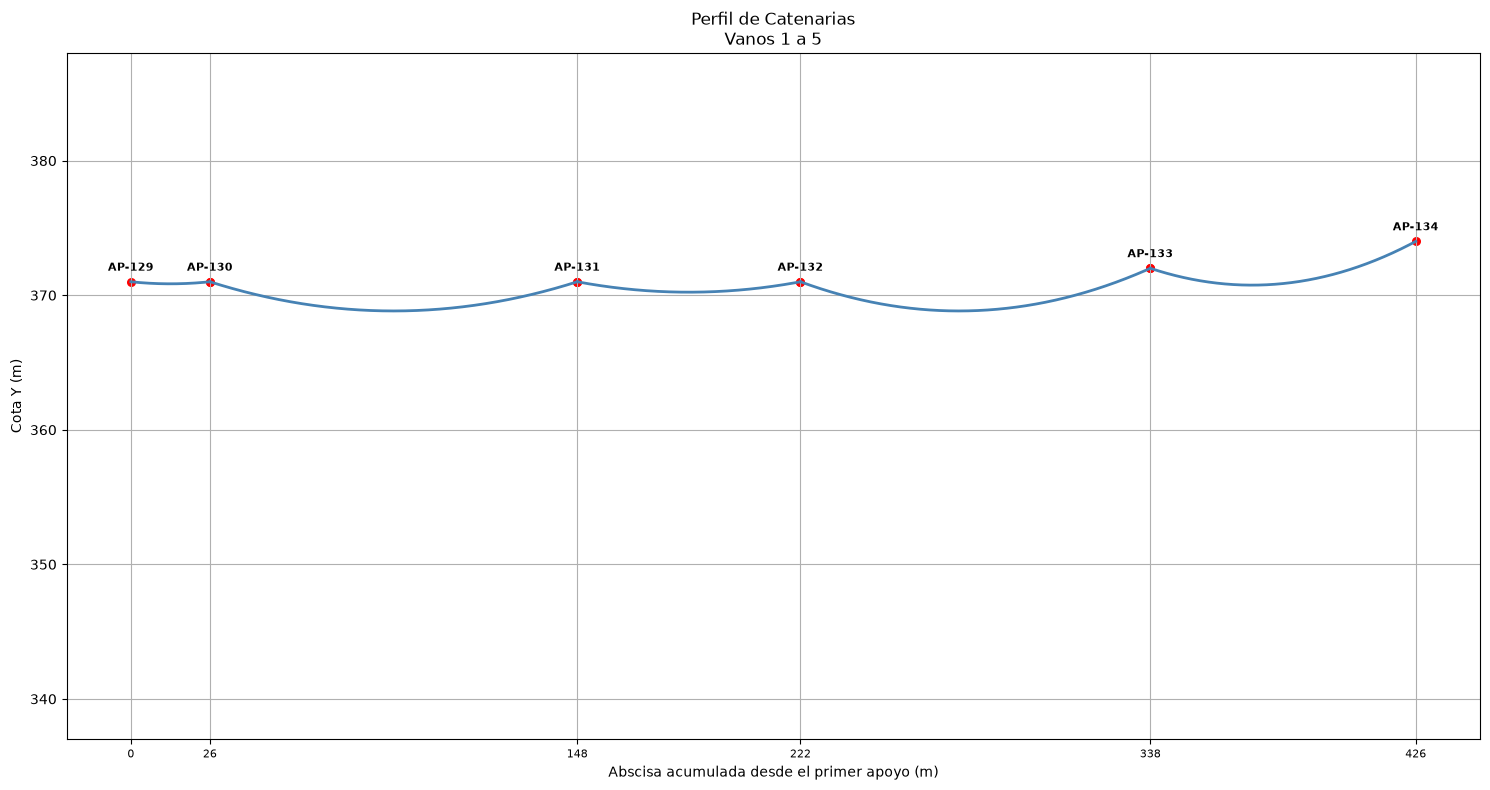

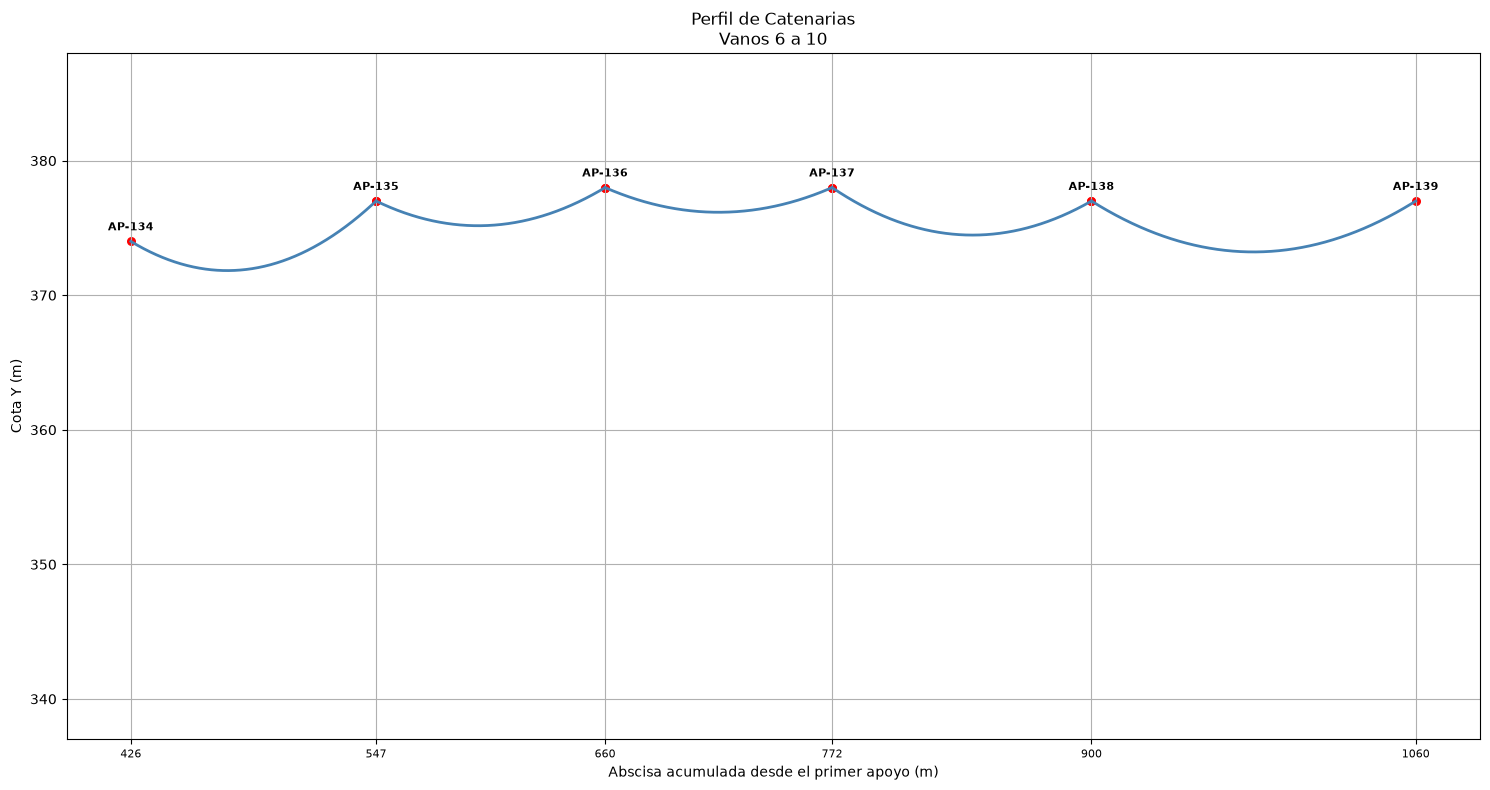

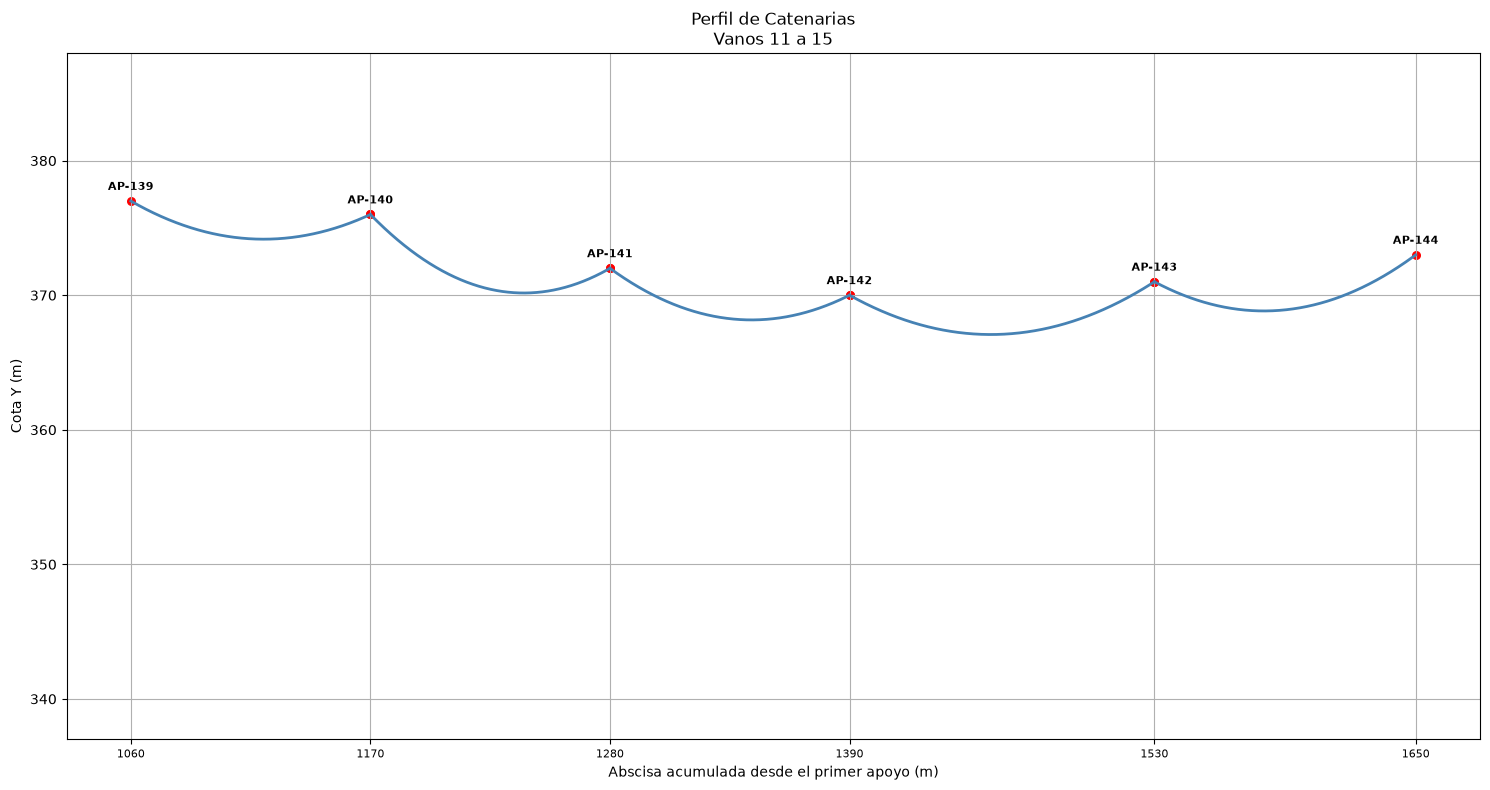

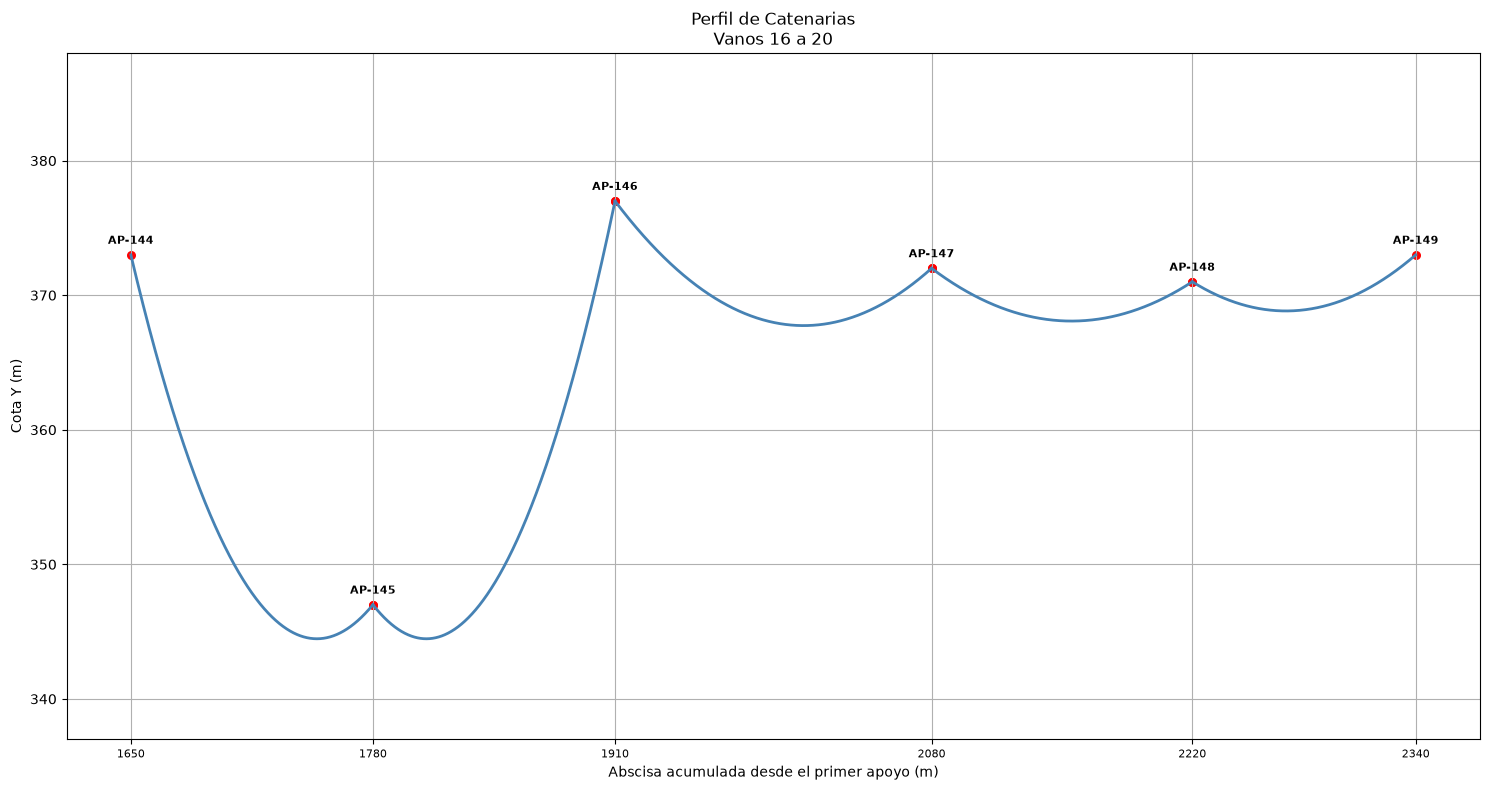

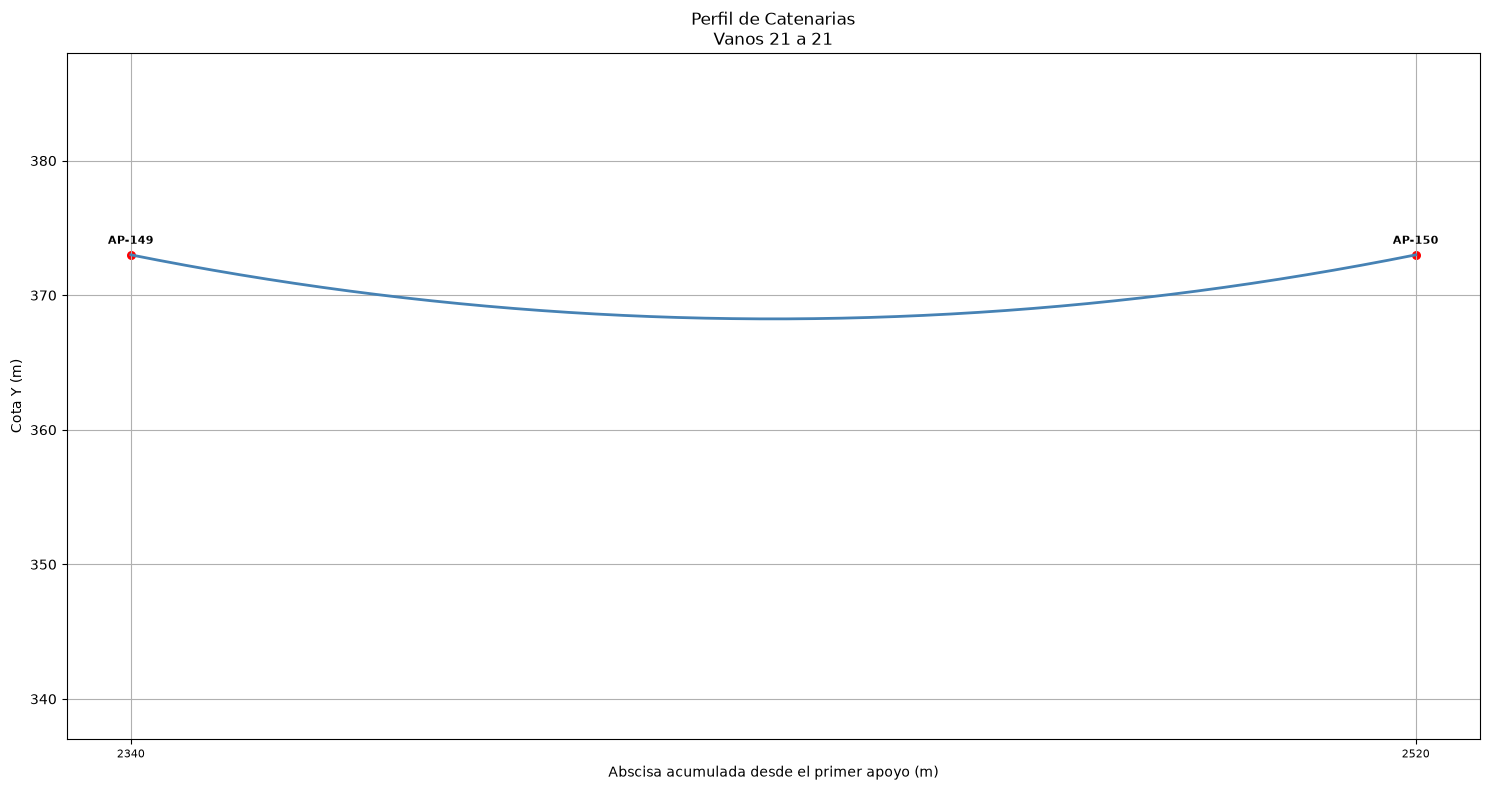


Longitud total = 2536.28 m

Generando DXF...
DXF generado correctamente:
PERFIL_CATENARIAS.dxf

PDF generado correctamente:
PERFIL_CATENARIAS.pdf

Excel generado correctamente:
RESULTADOS_CATENARIAS.xlsx


In [ ]:
!pip install ezdxf

import ezdxf

import tkinter as tk
from tkinter import filedialog, messagebox
import shutil
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import fsolve
from matplotlib.backends.backend_pdf import PdfPages

# =====================================================
# CARGAR ARCHIVO DE DATOS
# =====================================================

def subir_archivo():
    archivo = filedialog.askopenfilename(
        title="Seleccionar archivo Excel",
        filetypes=[("Archivos Excel", "*.xlsx")]
    )

    if archivo:
        # Carpeta Programacion (directorio actual)
        carpeta_destino = os.getcwd()

        destino = os.path.join(
            carpeta_destino,
            os.path.basename(archivo)
        )

        shutil.copy2(archivo, destino)

        messagebox.showinfo(
            "Éxito",
            f"Archivo copiado en:\n{destino}"
        )

root = tk.Tk()
root.title("Cargar archivo Excel")
root.geometry("300x150")

boton = tk.Button(
    root,
    text="Seleccionar archivo",
    command=subir_archivo
)

boton.pack(expand=True)

root.mainloop()


# ===================================================== voy acá
# CONFIGURACIÓN
# =====================================================

ARCHIVO = "DATOS.xlsx"

VANOS_POR_PAGINA = 5

# =====================================================
# LEER EXCEL
# =====================================================

df = pd.read_excel(
    ARCHIVO,
    sheet_name=0,
    header=None
)

# =====================================================
# LEER APOYOS Y COORDENADAS
# =====================================================

puntos = []

fila = 1

while fila < len(df):

    apoyo = df.iloc[fila, 0]
    x = df.iloc[fila, 1]
    y = df.iloc[fila, 2]

    if pd.isna(x) or pd.isna(y):
        break

    puntos.append(
        (
            str(apoyo),
            float(x),
            float(y)
        )
    )

    fila += 1

# =====================================================
# LEER FLECHAS
# =====================================================

flechas = []

fila = 2

while fila < len(df):

    f = df.iloc[fila, 4]

    if pd.isna(f):
        break

    flechas.append(float(f))

    fila += 1

# =====================================================
# VALIDACIÓN
# =====================================================

n_puntos = len(puntos)
n_vanos = n_puntos - 1

print(f"Puntos detectados : {n_puntos}")
print(f"Vanos detectados  : {n_vanos}")
print(f"Flechas detectadas: {len(flechas)}")

if len(flechas) != n_vanos:

    raise ValueError(
        f"Se encontraron {n_puntos} puntos "
        f"({n_vanos} vanos) y "
        f"{len(flechas)} flechas."
    )

# =====================================================
# FUNCIÓN DE CATENARIA
# =====================================================

def calcular_catenaria(x1, y1, x2, y2, flecha):

    y_ref = min(y1, y2)

    def sistema(v):

        a, b, c = v

        eq1 = a*np.cosh((x1-b)/a) + c - y1

        eq2 = a*np.cosh((x2-b)/a) + c - y2

        y_min = a + c

        eq3 = (y_ref - y_min) - flecha

        return [eq1, eq2, eq3]

    a0 = max(abs(x2-x1), 10)

    b0 = (x1+x2)/2

    c0 = y_ref - flecha - a0

    a, b, c = fsolve(
        sistema,
        [a0, b0, c0]
    )

    longitud = abs(
        a * (
            np.sinh((x2-b)/a)
            - np.sinh((x1-b)/a)
        )
    )

    return a, b, c, longitud


# =====================================================
# CALCULAR VANOS
# =====================================================

resultados = []
longitud_total = 0

for i in range(n_vanos):

    apoyo1, x1, y1 = puntos[i]
    apoyo2, x2, y2 = puntos[i + 1]

    flecha = flechas[i]

    a, b, c, L = calcular_catenaria(
        x1,
        y1,
        x2,
        y2,
        flecha
    )

    longitud_total += L

    resultados.append({
        "Vano": i + 1,
        "Apoyo Inicial": apoyo1,
        "Apoyo Final": apoyo2,
        "Flecha (m)": flecha,
        "Longitud (m)": round(L, 3),
        "a": round(a, 6),
        "b": round(b, 6),
        "c": round(c, 6)
    })

    print(
        f"Vano {i+1:02d} | "
        f"{apoyo1} -> {apoyo2} | "
        f"L = {L:.2f} m"
    )


# =====================================================
# ABSCISADO GLOBAL
# =====================================================

x0_global = puntos[0][1]

# =====================================================
# ESCALA FIJA DEL EJE Y
# =====================================================

y_global = [p[2] for p in puntos]

y_min_global = min(y_global) - 10
y_max_global = max(y_global) + 10

print("\nESCALA VERTICAL GLOBAL")
print(f"Y mínimo = {y_min_global:.2f}")
print(f"Y máximo = {y_max_global:.2f}")

# =====================================================
# GRAFICAR EN PANTALLA
# =====================================================

for inicio in range(0, n_vanos, VANOS_POR_PAGINA):

    fin = min(
        inicio + VANOS_POR_PAGINA,
        n_vanos
    )

    plt.figure(figsize=(15,8))

    puntos_x = []
    puntos_y = []

    for i in range(inicio, fin):

        apoyo1, x1, y1 = puntos[i]
        apoyo2, x2, y2 = puntos[i+1]

        flecha = flechas[i]

        a, b, c, L = calcular_catenaria(
            x1,
            y1,
            x2,
            y2,
            flecha
        )

        x = np.linspace(x1, x2, 800)

        y = a*np.cosh((x-b)/a) + c

        plt.plot(
            x,
            y,
            color="steelblue",
            linewidth=2
        )

        puntos_x.extend([x1, x2])
        puntos_y.extend([y1, y2])

    plt.scatter(
        puntos_x,
        puntos_y,
        color="red",
        s=30
    )

    x_apoyos = []
    etiquetas = []

    for j in range(inicio, fin + 1):

        apoyo, x, y = puntos[j]

        plt.annotate(
            apoyo,
            (x,y),
            xytext=(0,8),
            textcoords="offset points",
            fontsize=8,
            ha="center",
            fontweight="bold"
        )

        x_apoyos.append(x)
        etiquetas.append(
            f"{x-x0_global:.0f}"
        )

    plt.xticks(
        x_apoyos,
        etiquetas,
        fontsize=8
    )

    plt.ylim(
        y_min_global,
        y_max_global
    )

    plt.grid(True)

    plt.xlabel(
        "Abscisa acumulada desde el primer apoyo (m)"
    )

    plt.ylabel(
        "Cota Y (m)"
    )

    plt.title(
        f"Perfil de Catenarias\nVanos {inicio+1} a {fin}"
    )

    plt.tight_layout()

    plt.show()

# =====================================================
# EXPORTAR RESULTADOS EN EXCEL
# =====================================================

df_resultados = pd.DataFrame(resultados)

df_resultados.loc[len(df_resultados)] = {
    "Vano": "",
    "Apoyo Inicial": "",
    "Apoyo Final": "",
    "Flecha (m)": "",
    "Longitud (m)": round(longitud_total,3),
    "a": "",
    "b": "",
    "c": ""
}

df_resultados.to_excel(
    "RESULTADOS_CATENARIAS.xlsx",
    index=False
)

print("\nLongitud total =", round(longitud_total,2), "m")

# =====================================================
# GENERAR PDF
# =====================================================

nombre_pdf = "PERFIL_CATENARIAS.pdf"

with PdfPages(nombre_pdf) as pdf:

    for inicio in range(0, n_vanos, VANOS_POR_PAGINA):

        fin = min(
            inicio + VANOS_POR_PAGINA,
            n_vanos
        )

        fig, ax = plt.subplots(
            figsize=(15,8)
        )

        puntos_x = []
        puntos_y = []

        for i in range(inicio, fin):

            apoyo1, x1, y1 = puntos[i]
            apoyo2, x2, y2 = puntos[i+1]

            flecha = flechas[i]

            a, b, c, L = calcular_catenaria(
                x1,
                y1,
                x2,
                y2,
                flecha
            )

            x = np.linspace(x1, x2, 800)

            y = a*np.cosh((x-b)/a) + c

            ax.plot(
                x,
                y,
                color="steelblue",
                linewidth=2
            )

            puntos_x.extend([x1, x2])
            puntos_y.extend([y1, y2])

        ax.scatter(
            puntos_x,
            puntos_y,
            color="red",
            s=30
        )

        x_apoyos = []
        etiquetas = []

        for j in range(inicio, fin + 1):

            apoyo, x, y = puntos[j]

            ax.annotate(
                apoyo,
                (x,y),
                xytext=(0,8),
                textcoords="offset points",
                fontsize=8,
                ha="center",
                fontweight="bold"
            )

            x_apoyos.append(x)

            etiquetas.append(
                f"{x-x0_global:.0f}"
            )

        ax.set_xticks(x_apoyos)

        ax.set_xticklabels(
            etiquetas,
            fontsize=8
        )

        ax.set_ylim(
            y_min_global,
            y_max_global
        )

        ax.grid(True)

        ax.set_xlabel(
            "Abscisa acumulada desde el primer apoyo (m)"
        )

        ax.set_ylabel(
            "Cota Y (m)"
        )

        ax.set_title(
            f"Perfil de Catenarias\nVanos {inicio+1} a {fin}"
        )

        pdf.savefig(
            fig,
            bbox_inches="tight"
        )

        plt.close(fig)


# =====================================================
# EXPORTACIÓN DXF
# =====================================================

print("\nGenerando DXF...")

doc = ezdxf.new("R2018")

msp = doc.modelspace()

capas = [
    ("CATENARIAS", 5),
    ("APOYOS", 1),
    ("PERFIL_APOYOS", 3),
    ("TEXTOS_APOYOS", 2),
    ("ABSCISAS", 4)
]

for nombre, color in capas:

    if nombre not in doc.layers:

        doc.layers.new(
            nombre,
            dxfattribs={"color": color}
        )

# =====================================================
# PERFIL DE APOYOS
# =====================================================

perfil = []

for apoyo, x, y in puntos:

    perfil.append((x, y))

msp.add_lwpolyline(
    perfil,
    dxfattribs={
        "layer": "PERFIL_APOYOS"
    }
)

# =====================================================
# APOYOS
# =====================================================

radio_apoyo = 0.30

for apoyo, x, y in puntos:

    msp.add_circle(
        center=(x, y),
        radius=radio_apoyo,
        dxfattribs={
            "layer": "APOYOS"
        }
    )

# =====================================================
# TEXTOS DE APOYO
# =====================================================

for apoyo, x, y in puntos:

    texto = msp.add_text(
        str(apoyo),
        dxfattribs={
            "height": 1.50,
            "layer": "TEXTOS_APOYOS"
        }
    )

    texto.dxf.insert = (
        x,
        y + 2
    )

# =====================================================
# ABSCISADO
# =====================================================

x0_global = puntos[0][1]

for apoyo, x, y in puntos:

    abscisa = x - x0_global

    texto = msp.add_text(
        f"{abscisa:.0f}",
        dxfattribs={
            "height": 1.20,
            "layer": "ABSCISAS"
        }
    )

    texto.dxf.insert = (
        x,
        y - 3
    )

# =====================================================
# CATENARIAS
# =====================================================

for i in range(n_vanos):

    apoyo1, x1, y1 = puntos[i]

    apoyo2, x2, y2 = puntos[i + 1]

    flecha = flechas[i]

    a, b, c, L = calcular_catenaria(
        x1,
        y1,
        x2,
        y2,
        flecha
    )

    x = np.linspace(
        x1,
        x2,
        300
    )

    y = a * np.cosh(
        (x - b) / a
    ) + c

    vertices = list(zip(x, y))

    msp.add_lwpolyline(
        vertices,
        dxfattribs={
            "layer": "CATENARIAS"
        }
    )

# =====================================================
# GUARDAR ARCHIVO
# =====================================================

nombre_dxf = "PERFIL_CATENARIAS.dxf"

doc.saveas(nombre_dxf)

print("DXF generado correctamente:")
print(nombre_dxf)


print("\nPDF generado correctamente:")
print(nombre_pdf)

print("\nExcel generado correctamente:")
print("RESULTADOS_CATENARIAS.xlsx")

In [3]:
import tkinter as tk
from tkinter import filedialog, messagebox
import shutil
import os

# =====================================================
# CARGAR ARCHIVO DE DATOS
# =====================================================
root = tk.Tk()
root.title("Cargar archivo Excel")
root.attributes('-fullscreen', True)

archivo = ""  # Variable global

def salir_pantalla_completa(event=None):
    root.attributes('-fullscreen', False)

root.bind('<Escape>', salir_pantalla_completa)

def activar_pantalla_completa(event=None):
    root.attributes('-fullscreen', True)

root.bind('<F11>', activar_pantalla_completa)

def subir_archivo():
    global archivo

    archivo = filedialog.askopenfilename(
        title="Seleccionar archivo Excel",
        filetypes=[("Archivos Excel", "*.xlsx")]
    )

    if archivo:
        carpeta_destino = os.getcwd()

        destino = os.path.join(
            carpeta_destino,
            os.path.basename(archivo)
        )

        shutil.copy2(archivo, destino)

        # Mostrar nombre del archivo al lado del botón
        letrero_confir.config(
            text=f"✅ {os.path.basename(archivo)}"
        )

        messagebox.showinfo(
            "Éxito",
            f"Archivo copiado en:\n{destino}"
        )

# -----------------------------------------------------
# Botón para seleccionar archivo
# -----------------------------------------------------
boton1 = tk.Button(
    root,
    text="Seleccionar archivo",
    command=subir_archivo
)
boton1.place(x=100, y=100)

# -----------------------------------------------------
# Label al lado del botón
# -----------------------------------------------------
letrero_confir = tk.Label(
    root,
    text="",
    font=("Arial", 14),
    fg="green"
)

# Posicionado al lado derecho de boton1
letrero_confir.place(x=250, y=100)

# -----------------------------------------------------
# Botón para cerrar la ventana
# -----------------------------------------------------
boton_cerrar = tk.Button(
    root,
    text="Finalizar",
    command=root.destroy
)

boton_cerrar.place(x=1800, y=1000)



root.mainloop()

Versión actualizada del código 19-09-2026.
El código se organiza en 11 ítems, definiendo funciones para la ejecución de cada paso. 
Las funciones tienen el propósito de ser ejecutadas por botones programados dentro de la interfaz gráfica

Presenta interfaz completa y código acomodado de la siguiente manera:

0. Importación de librerías y configuración de variables iniciales
1. Cargue de archivo
2. Leer información de archivo base (el archivo debe ser llamado Datos)
3. Extraer la información de los puntos GPS de los apoyos y flechas correspondientes a cada vano
4. Calcular la función cuadrática que define la catenaria (a través del cálculo de longitud de la parábola)
5. Calcular cada vano mediante un ciclo For
6. Extraer la información necesaria de cada vano para graficarla
7. Grafica en pantalla las catenarias, considerando los puntos máximos, identificación de apoyos y abscisado.
8. Exporta el archivo XLSX con la información de entrada y los coeficientes de la parábola
9. Exporta el PDF con las gráficas de las catenarias (cada 5 vanos)
10. Exporta el DXF en escala 1:1
11. Configuración de la interfaz gráfica y botones asociados a las funciones definidas.
    El botón Subir archivo: Abre la ventada para subir el archivo "DATOS"
    El botón calcular gráficas: ejecuta el item 2 al 7
    Los botones de exportación: Generan los documentos dentro de la carpeta base del programa
    El botón finalizar: Cierra la interfaz y finaliza el programa.

Archivo Excel leído correctamente
Puntos detectados : 23
Vanos detectados  : 22
Flechas detectadas: 22
Vano 01 | AP-129 -> AP-130 | L = 26.20 m
Vano 02 | AP-130 -> AP-131 | L = 121.90 m
Vano 03 | AP-131 -> AP-132 | L = 74.02 m
Vano 04 | AP-132 -> AP-133 | L = 116.17 m
Vano 05 | AP-133 -> AP-134 | L = 88.16 m
Vano 06 | AP-134 -> AP-135 | L = 121.31 m
Vano 07 | AP-135 -> AP-136 | L = 113.13 m
Vano 08 | AP-136 -> AP-137 | L = 112.08 m
Vano 09 | AP-137 -> AP-138 | L = 128.19 m
Vano 10 | AP-138 -> AP-139 | L = 160.24 m
Vano 11 | AP-139 -> AP-140 | L = 110.13 m
Vano 12 | AP-140 -> AP-141 | L = 110.38 m
Vano 13 | AP-141 -> AP-142 | L = 110.20 m
Vano 14 | AP-142 -> AP-143 | L = 140.22 m
Vano 15 | AP-143 -> AP-144 | L = 120.23 m
Vano 16 | AP-144 -> AP-145 | L = 135.38 m
Vano 17 | AP-145 -> AP-146 | L = 136.81 m
Vano 18 | AP-146 -> AP-147 | L = 170.74 m
Vano 19 | AP-147 -> AP-148 | L = 140.22 m
Vano 20 | AP-148 -> AP-149 | L = 120.23 m
Vano 21 | AP-149 -> AP-150 | L = 180.34 m
Vano 22 | AP-150 -

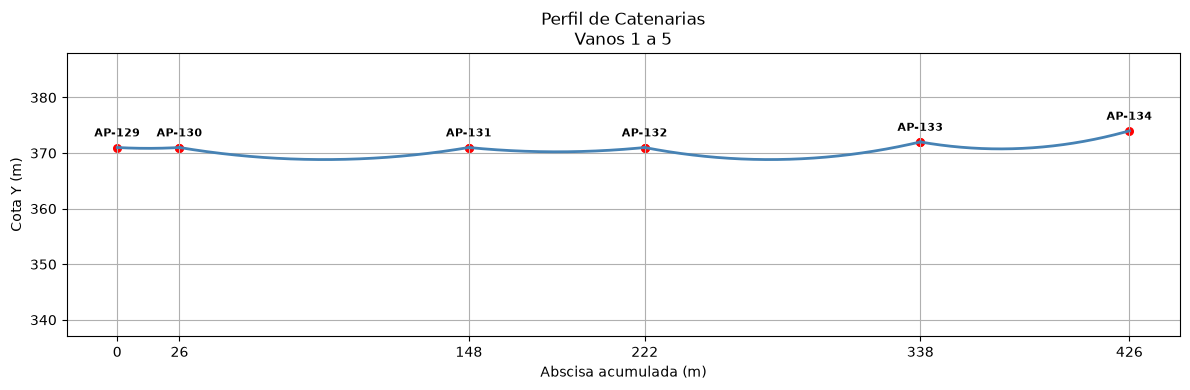

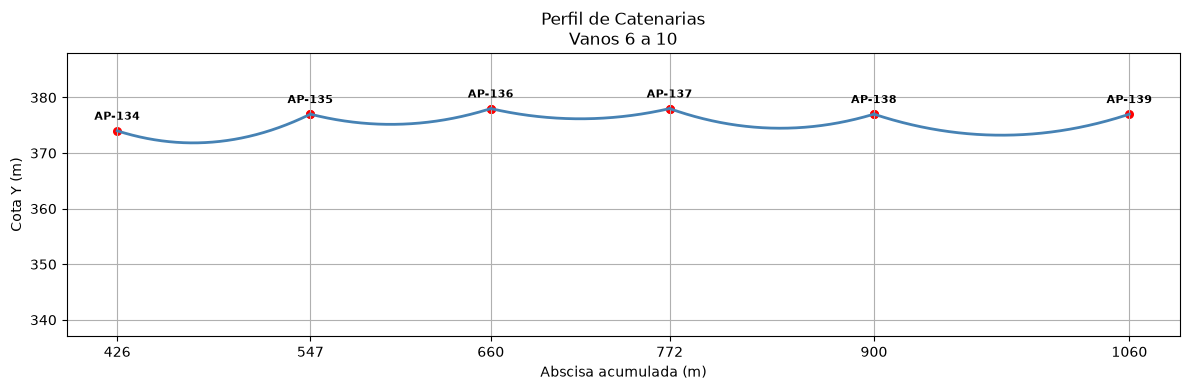

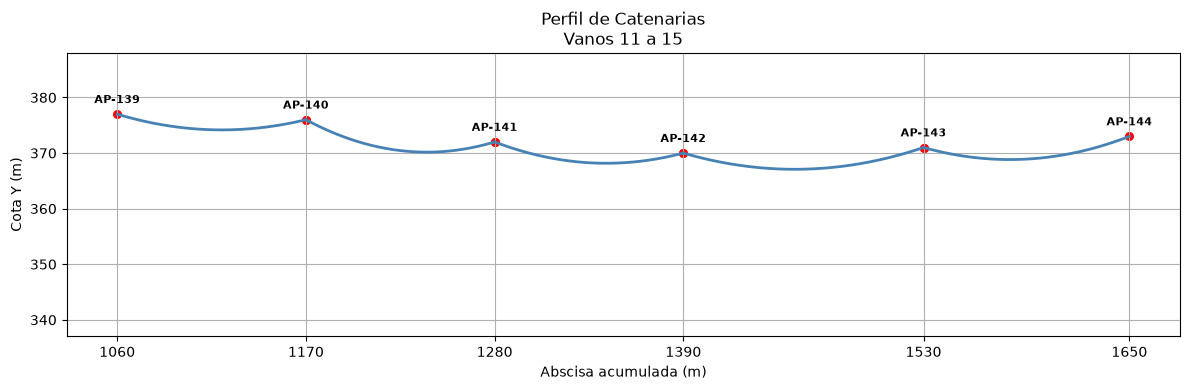

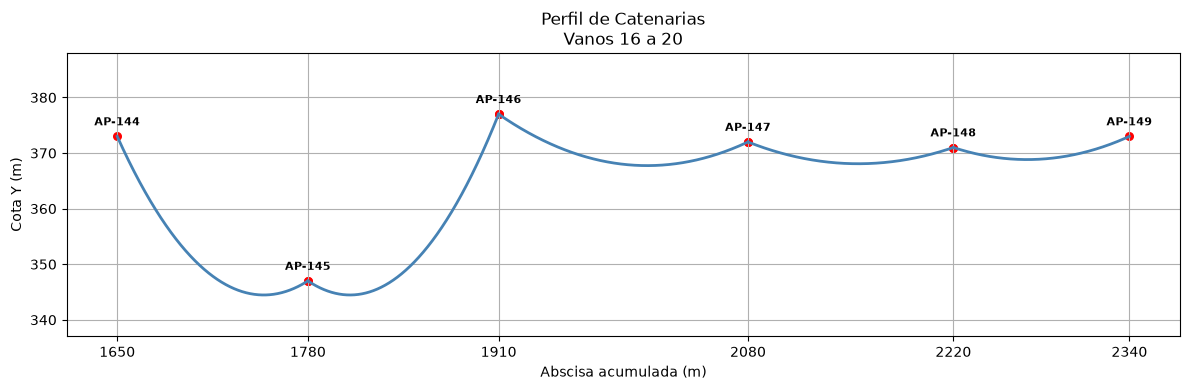

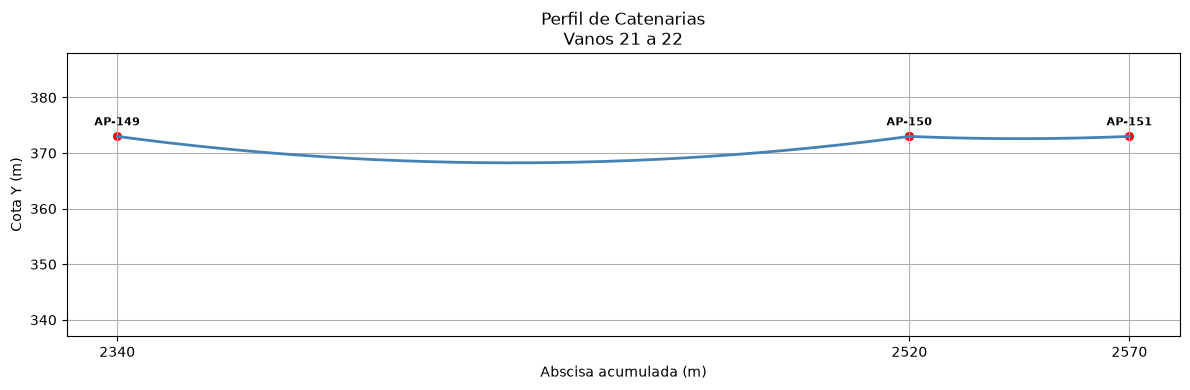

In [ ]:
# =====================================================
# IMPORTACIÓN DE LIBRERÍAS
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ezdxf

from scipy.optimize import fsolve
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg

import tkinter as tk
from tkinter import filedialog, messagebox

import shutil
import os

# pandas
# numpy
# matplotlib
# ezdxf
# scipy
# etc.

# =====================================================
# VARIABLES GLOBALES
# =====================================================

archivo = ""

df = None

puntos = []
flechas = []
resultados = []

n_puntos = 0
n_vanos = 0

longitud_total = 0

x0_global = 0
y_min_global = 0
y_max_global = 0

VANOS_POR_PAGINA = 5

# =====================================================
# 1. CARGAR ARCHIVO
# =====================================================

def subir_archivo():

    global archivo

    archivo = filedialog.askopenfilename(
        title="Seleccionar archivo Excel",
        filetypes=[("Excel", "*.xlsx")]
    )

    if archivo:

        destino = os.path.join(
            os.getcwd(),
            os.path.basename(archivo)
        )

        if os.path.abspath(archivo) != os.path.abspath(destino):

            shutil.copy2(
                archivo,
                destino
            )

        lbl_archivo.config(
            text=f"✅ Archivo cargado correctamente: {os.path.basename(archivo)}"
        )

        messagebox.showinfo(
            "Correcto",
            "Archivo cargado correctamente."
        )


# =====================================================
# 2. LEER EL ARCHIVO EXCEL
# =====================================================

def leer_excel():

    global df

    df = pd.read_excel(
        archivo,
        sheet_name=0,
        header=None
    )

    print("Archivo Excel leído correctamente")


# =====================================================
# 3. EXTRAER INFORMACIÓN DE APOYOS Y FLECHAS
# =====================================================

def extraer_datos():

    global puntos
    global flechas
    global n_puntos
    global n_vanos

    fila = 1

    while fila < len(df):

        apoyo = df.iloc[fila, 0]
        x = df.iloc[fila, 1]
        y = df.iloc[fila, 2]

        if pd.isna(x) or pd.isna(y):
            break

        puntos.append(
            (
                str(apoyo),
                float(x),
                float(y)
            )
        )

        fila += 1

    fila = 2

    while fila < len(df):

        f = df.iloc[fila, 4]

        if pd.isna(f):
            break

        flechas.append(float(f))

        fila += 1

    n_puntos = len(puntos)
    n_vanos = n_puntos - 1

    print(f"Puntos detectados : {n_puntos}")
    print(f"Vanos detectados  : {n_vanos}")
    print(f"Flechas detectadas: {len(flechas)}")

    if len(flechas) != n_vanos:

        raise ValueError(
            f"Se encontraron {n_puntos} puntos "
            f"({n_vanos} vanos) y "
            f"{len(flechas)} flechas."
        )


# =====================================================
# 4. CALCULAR LA FUNCIÓN DE LA CATENARIA
# =====================================================

def calcular_catenaria(x1, y1, x2, y2, flecha):

    y_ref = min(y1, y2)

    def sistema(v):

        a, b, c = v

        eq1 = a * np.cosh((x1 - b) / a) + c - y1

        eq2 = a * np.cosh((x2 - b) / a) + c - y2

        y_min = a + c

        eq3 = (y_ref - y_min) - flecha

        return [eq1, eq2, eq3]

    a0 = max(abs(x2 - x1), 10)

    b0 = (x1 + x2) / 2

    c0 = y_ref - flecha - a0

    a, b, c = fsolve(
        sistema,
        [a0, b0, c0]
    )

    longitud = abs(
        a * (
            np.sinh((x2 - b) / a)
            - np.sinh((x1 - b) / a)
        )
    )

    return a, b, c, longitud


# =====================================================
# 5. CALCULAR CADA VANO
# =====================================================

def calcular_vanos():

    global resultados
    global longitud_total

    for i in range(n_vanos):

        apoyo1, x1, y1 = puntos[i]
        apoyo2, x2, y2 = puntos[i + 1]

        flecha = flechas[i]

        a, b, c, L = calcular_catenaria(
            x1,
            y1,
            x2,
            y2,
            flecha
        )

        longitud_total += L

        resultados.append({

            "Vano": i + 1,
            "Apoyo Inicial": apoyo1,
            "Apoyo Final": apoyo2,
            "Flecha (m)": flecha,
            "Longitud (m)": round(L, 3),
            "a": round(a, 6),
            "b": round(b, 6),
            "c": round(c, 6)

        })

        print(
            f"Vano {i+1:02d} | "
            f"{apoyo1} -> {apoyo2} | "
            f"L = {L:.2f} m"
        )


# =====================================================
# 6. PREPARAR LAS GRÁFICAS
# =====================================================

def preparar_graficas():

    global x0_global
    global y_min_global
    global y_max_global

    x0_global = puntos[0][1]

    y_global = [p[2] for p in puntos]

    y_min_global = min(y_global) - 10
    y_max_global = max(y_global) + 10

    print("\nESCALA VERTICAL GLOBAL")
    print(f"Y mínimo = {y_min_global:.2f}")
    print(f"Y máximo = {y_max_global:.2f}")


# =====================================================
# 7. GRAFICAR EN PANTALLA
# =====================================================

def mostrar_graficas():

    for widget in frame_graficas.winfo_children():
        widget.destroy()

    for inicio in range(
        0,
        n_vanos,
        VANOS_POR_PAGINA
    ):

        fin = min(
            inicio + VANOS_POR_PAGINA,
            n_vanos
        )

        fig, ax = plt.subplots(
            figsize=(12, 4)
        )

        puntos_x = []
        puntos_y = []

        for i in range(inicio, fin):

            apoyo1, x1, y1 = puntos[i]
            apoyo2, x2, y2 = puntos[i+1]

            flecha = flechas[i]

            a, b, c, _ = calcular_catenaria(
                x1,
                y1,
                x2,
                y2,
                flecha
            )

            x = np.linspace(
                x1,
                x2,
                800
            )

            y = a*np.cosh(
                (x-b)/a
            ) + c

            ax.plot(
                x,
                y,
                color="steelblue",
                linewidth=2
            )

            puntos_x.extend([x1, x2])
            puntos_y.extend([y1, y2])

        ax.scatter(
            puntos_x,
            puntos_y,
            color="red",
            s=30
        )

        x_apoyos = []
        etiquetas = []

        for j in range(inicio, fin+1):

            apoyo, x, y = puntos[j]

            ax.annotate(
                apoyo,
                (x, y),
                xytext=(0, 8),
                textcoords="offset points",
                fontsize=8,
                ha="center",
                fontweight="bold"
            )

            x_apoyos.append(x)

            etiquetas.append(
                f"{x-x0_global:.0f}"
            )

        ax.set_xticks(
            x_apoyos
        )

        ax.set_xticklabels(
            etiquetas
        )

        ax.set_ylim(
            y_min_global,
            y_max_global
        )

        ax.grid(True)

        ax.set_title(
            f"Perfil de Catenarias\nVanos {inicio+1} a {fin}"
        )

        ax.set_xlabel(
            "Abscisa acumulada (m)"
        )

        ax.set_ylabel(
            "Cota Y (m)"
        )

        fig.tight_layout()

        canvas_figura = FigureCanvasTkAgg(
            fig,
            master=frame_graficas
        )

        canvas_figura.draw()

        canvas_figura.get_tk_widget().pack(
            fill="x",
            padx=20,
            pady=10
        )

# BOTON DE CÁLCULO

def ejecutar_calculo():

    global resultados
    global puntos
    global flechas
    global longitud_total

    if archivo == "":

        messagebox.showwarning(
            "Advertencia",
            "Seleccione un archivo."
        )

        return

    try:

        puntos.clear()
        flechas.clear()
        resultados.clear()

        longitud_total = 0

        leer_excel()

        extraer_datos()

        calcular_vanos()

        preparar_graficas()

        mostrar_graficas()

        lbl_estado.config(
            text="✅ Cálculo completado correctamente."
        )

        messagebox.showinfo(
            "Correcto",
            "Cálculo terminado."
        )

    except Exception as e:

        messagebox.showerror(
            "Error",
            str(e)
        )


# =====================================================
# 8. EXPORTAR RESULTADOS A XLSX
# =====================================================

def exportar_excel():

    df_resultados = pd.DataFrame(resultados)

    df_resultados.loc[len(df_resultados)] = {

        "Vano": "",
        "Apoyo Inicial": "",
        "Apoyo Final": "",
        "Flecha (m)": "",
        "Longitud (m)": round(longitud_total, 3),
        "a": "",
        "b": "",
        "c": ""

    }

    df_resultados.to_excel(
        "RESULTADOS_CATENARIAS.xlsx",
        index=False
    )

    print("\nExcel generado correctamente")
    messagebox.showinfo(
    "Excel",
    "Excel generado correctamente."
    )


   


# =====================================================
# 9. EXPORTAR GRÁFICAS A PDF
# =====================================================

def exportar_pdf():

    nombre_pdf = "PERFIL_CATENARIAS.pdf"

    with PdfPages(nombre_pdf) as pdf:

        for inicio in range(0, n_vanos, VANOS_POR_PAGINA):

            fin = min(
                inicio + VANOS_POR_PAGINA,
                n_vanos
            )

            fig, ax = plt.subplots(
                figsize=(15, 8)
            )

            puntos_x = []
            puntos_y = []

            # ---------------------------------------------
            # DIBUJAR CATENARIAS
            # ---------------------------------------------

            for i in range(inicio, fin):

                apoyo1, x1, y1 = puntos[i]
                apoyo2, x2, y2 = puntos[i + 1]

                flecha = flechas[i]

                a, b, c, _ = calcular_catenaria(
                    x1,
                    y1,
                    x2,
                    y2,
                    flecha
                )

                x = np.linspace(x1, x2, 800)

                y = a * np.cosh(
                    (x - b) / a
                ) + c

                ax.plot(
                    x,
                    y,
                    color="steelblue",
                    linewidth=2
                )

                puntos_x.extend([x1, x2])
                puntos_y.extend([y1, y2])

            # ---------------------------------------------
            # DIBUJAR APOYOS
            # ---------------------------------------------

            ax.scatter(
                puntos_x,
                puntos_y,
                color="red",
                s=30
            )

            # ---------------------------------------------
            # ETIQUETAS DE APOYOS
            # ---------------------------------------------

            x_apoyos = []
            etiquetas = []

            for j in range(inicio, fin + 1):

                apoyo, x, y = puntos[j]

                # Nombre o número del apoyo

                ax.annotate(
                    str(apoyo),
                    (x, y),
                    xytext=(0, 8),
                    textcoords="offset points",
                    fontsize=8,
                    ha="center",
                    fontweight="bold"
                )

                x_apoyos.append(x)

                etiquetas.append(
                    f"{x - x0_global:.0f}"
                )

            # ---------------------------------------------
            # ABSCISAS
            # ---------------------------------------------

            ax.set_xticks(x_apoyos)

            ax.set_xticklabels(
                etiquetas,
                fontsize=8
            )

            # ---------------------------------------------
            # ESCALA FIJA EN Y
            # ---------------------------------------------

            ax.set_ylim(
                y_min_global,
                y_max_global
            )

            # ---------------------------------------------
            # FORMATO GENERAL
            # ---------------------------------------------

            ax.grid(True)

            ax.set_xlabel(
                "Abscisa acumulada desde el primer apoyo (m)"
            )

            ax.set_ylabel(
                "Cota Y (m)"
            )

            ax.set_title(
                f"Perfil de Catenarias\nVanos {inicio+1} a {fin}"
            )

            plt.tight_layout()

            pdf.savefig(
                fig,
                bbox_inches="tight"
            )

            plt.close(fig)

    print("\nPDF generado correctamente:")
    print(nombre_pdf)
    messagebox.showinfo(
    "PDF",
    "PDF generado correctamente."
)

# =====================================================
# 10. EXPORTAR PERFIL A DXF
# =====================================================

def exportar_dxf():

    print("\nGenerando DXF...")

    doc = ezdxf.new("R2018")

    msp = doc.modelspace()

    # -------------------------------------------------
    # CREAR CAPAS
    # -------------------------------------------------

    capas = [

        ("CATENARIAS", 5),
        ("APOYOS", 1),
        ("PERFIL_APOYOS", 3),
        ("TEXTOS_APOYOS", 2),
        ("ABSCISAS", 4)

    ]

    for nombre, color in capas:

        if nombre not in doc.layers:

            doc.layers.new(
                nombre,
                dxfattribs={
                    "color": color
                }
            )

    # -------------------------------------------------
    # PERFIL DE APOYOS
    # -------------------------------------------------

    perfil = []

    for apoyo, x, y in puntos:

        perfil.append((x, y))

    msp.add_lwpolyline(

        perfil,

        dxfattribs={
            "layer": "PERFIL_APOYOS"
        }

    )

    # -------------------------------------------------
    # APOYOS
    # -------------------------------------------------

    radio_apoyo = 0.30

    for apoyo, x, y in puntos:

        msp.add_circle(

            center=(x, y),
            radius=radio_apoyo,

            dxfattribs={
                "layer": "APOYOS"
            }

        )

    # -------------------------------------------------
    # TEXTOS DE APOYOS
    # -------------------------------------------------

    for indice, (apoyo, x, y) in enumerate(puntos):

        texto = msp.add_text(

            f"{indice+1} - {apoyo}",

            dxfattribs={
                "height": 1.50,
                "layer": "TEXTOS_APOYOS"
            }

        )

        texto.dxf.insert = (

            x,
            y + 2

        )

    # -------------------------------------------------
    # ABSCISADO ACUMULADO
    # -------------------------------------------------

    for apoyo, x, y in puntos:

        abscisa = x - x0_global

        texto = msp.add_text(

            f"{abscisa:.0f}",

            dxfattribs={
                "height": 1.20,
                "layer": "ABSCISAS"
            }

        )

        texto.dxf.insert = (

            x,
            y - 3

        )

    # -------------------------------------------------
    # CATENARIAS
    # -------------------------------------------------

    for i in range(n_vanos):

        apoyo1, x1, y1 = puntos[i]

        apoyo2, x2, y2 = puntos[i + 1]

        flecha = flechas[i]

        a, b, c, L = calcular_catenaria(

            x1,
            y1,
            x2,
            y2,
            flecha

        )

        x = np.linspace(
            x1,
            x2,
            300
        )

        y = a * np.cosh(
            (x - b) / a
        ) + c

        vertices = list(zip(x, y))

        msp.add_lwpolyline(

            vertices,

            dxfattribs={
                "layer": "CATENARIAS"
            }

        )

    # -------------------------------------------------
    # GUARDAR DXF
    # -------------------------------------------------

    nombre_dxf = "PERFIL_CATENARIAS.dxf"

    doc.saveas(nombre_dxf)

    print("DXF generado correctamente:")
    print(nombre_dxf)
    messagebox.showinfo(
    "DXF",
    "DXF generado correctamente."
)

# =====================================================
# 11.INTERFAZ GRÁFICA :D
# =====================================================

# CONFIGURACIÓN DE LA VENTANA PRINCIPAL

root = tk.Tk()

root.title(
    "Generador de Catenarias"
)

root.attributes(
    '-fullscreen',
    True
)

def salir_pantalla_completa(event=None):

    root.attributes(
        '-fullscreen',
        False
    )

root.bind(
    '<Escape>',
    salir_pantalla_completa
)

def activar_pantalla_completa(event=None):

    root.attributes(
        '-fullscreen',
        True
    )

root.bind(
    '<F11>',
    activar_pantalla_completa
)

titulo = tk.Label(

    root,

    text="GENERADOR DE CATENARIAS",

    font=(
        "Arial",
        22,
        "bold"
    )

)

titulo.place(
    x=700,
    y=40
)


# BOTÓN PARA SUBIR ARCHIVO


btn_archivo = tk.Button(

    root,

    text="Seleccionar Archivo",

    width=25,

    bg="lightblue",

    font=("Arial", 10, "bold"),

    command=subir_archivo

)

btn_archivo.place(
    x=50,
    y=120
)

lbl_archivo = tk.Label(

    root,

    text="",

    fg="green",

    font=("Arial", 12)

)

lbl_archivo.place(
    x=50,
    y=160
)


btn_calcular = tk.Button(

    root,

    text="Calcular Catenarias",

    width=25,

    bg="lightblue",

    font=("Arial", 10, "bold"),

    command=ejecutar_calculo

)

btn_calcular.place(
    x=50,
    y=200
)


frame_exportacion = tk.LabelFrame(

    root,

    text="Exportaciones",

    font=("Arial", 12)

)

frame_exportacion.place(
    x=100,
    y=800,
    width=250,
    height=180
)





btn_excel = tk.Button(

    frame_exportacion,

    text="Exportar XLSX",

    width=20,

    bg="gold",

    font=("Arial", 10, "bold"),

    command=exportar_excel

)

btn_excel.pack(
    pady=10
)

btn_pdf = tk.Button(

    frame_exportacion,

    text="Exportar PDF",

    bg="gold",

    font=("Arial", 10, "bold"),

    width=20,

    command=exportar_pdf

)

btn_pdf.pack(
    pady=10
)

btn_dxf = tk.Button(

    frame_exportacion,

    text="Exportar DXF",

    width=20,

    bg="gold",

    font=("Arial", 10, "bold"),

    command=exportar_dxf

)

btn_dxf.pack(
    pady=10
)

lbl_estado = tk.Label(

    root,

    text="",

    font=("Arial", 12),

    fg="green"

)

lbl_estado.place(
    x=50,
    y=240
)




btn_salir = tk.Button(

    root,

    text="Finalizar",

    width=20,

    bg="red",

    font=("Arial", 10, "bold"),

    command=root.destroy

)

btn_salir.place(
    x=1700,
    y=1000
)


#PRUEBA

# -----------------------------------------------------
# ZONA SCROLLEABLE
# -----------------------------------------------------

contenedor = tk.Frame(root)

contenedor.place(
    x=400,
    y=100,
    width=1200,
    height=800
)

canvas_scroll = tk.Canvas(
    contenedor,
    bg="white"
)

scrollbar = tk.Scrollbar(
    contenedor,
    orient="vertical",
    command=canvas_scroll.yview
)

frame_graficas = tk.Frame(
    canvas_scroll,
    bg="white"
)

frame_graficas.bind(
    "<Configure>",
    lambda e:
    canvas_scroll.configure(
        scrollregion=canvas_scroll.bbox("all")
    )
)

canvas_scroll.create_window(
    (0, 0),
    window=frame_graficas,
    anchor="nw"
)

canvas_scroll.configure(
    yscrollcommand=scrollbar.set
)

canvas_scroll.pack(
    side="left",
    fill="both",
    expand=True
)

scrollbar.pack(
    side="right",
    fill="y"
)

for widget in frame_graficas.winfo_children():
    widget.destroy()


def _on_mousewheel(event):

    canvas_scroll.yview_scroll(
        int(-1*(event.delta/120)),
        "units"
    )

canvas_scroll.bind_all(
    "<MouseWheel>",
    _on_mousewheel
)



root.mainloop()

print(longitud_total)
